# Spatial Workload Shifting Across Geo-Distributed Data Centers

This notebook implements the **spatial-only** component of the research on carbon-aware workload scheduling. It uses regional, generation-weighted lifecycle carbon-intensity traces derived from ENTSO-E data and a synthetic cloud-workload stream.

## Research model

- The experiment covers a **24-hour workload-arrival window** divided into 96 slots of 15 minutes.
- Each region represents one data center with its own maximum IT power capacity and maximum number of concurrent jobs.
- Jobs are non-preemptive and have fixed arrival time, execution duration, and power demand.
- Every job is dispatched at its arrival slot. **The scheduler may change the execution region, but it may not postpone execution.**
- Once dispatched, a job remains in the selected data center until completion. This notebook does not model repeated live migration during execution.
- A short execution tail after the 24-hour arrival window is included so that jobs arriving near midnight can finish without truncating their carbon emissions.

## Policies compared

1. **Local-only:** execute in the job's origin region; no spatial migration.
2. **Home-first / carbon-unaware overflow:** use the origin region when feasible; otherwise use the first feasible alternative region in a fixed order. This is a capacity-aware, carbon-unaware operational baseline.
3. **Greedy Spatial (CI-only):** at arrival, choose the feasible region with the lowest estimated compute emissions; network emissions are counted in evaluation but ignored during selection.
4. **Greedy Spatial (compute + network):** at arrival, choose the feasible region minimizing estimated compute plus migration emissions. This is the principal online policy.
5. **MILP spatial oracle:** choose all jobs' destination regions jointly, with arrivals and execution times fixed. It is an offline, perfect-information benchmark, not an online implementation.

The main comparison is against the **home-first / carbon-unaware overflow** policy because it is capacity-feasible whenever the infrastructure has enough aggregate resources. The local-only result is retained as the unshifted reference and reports any capacity-related admission failures.

> **Data limitation:** the ENTSO-E generation files do not contain cloud-job telemetry. The workload is therefore synthetic and fully parameterized. Replace the synthetic profile with measured arrivals, durations, power, and transfer sizes when those traces become available.

## 0. Environment setup

Required packages: `pandas`, `numpy`, `matplotlib`, and `scipy` with `scipy.optimize.milp` support (SciPy 1.9 or later).

```python
%pip install pandas numpy matplotlib "scipy>=1.9"
```

Run the installation command only if the packages are missing in the active Jupyter environment.

In [35]:
from pathlib import Path
import re
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

SLOT_HOURS = 0.25
SLOTS_PER_HOUR = 4
SLOTS_PER_DAY = 96

# Explicit region-to-file mapping. No automatic file discovery is performed.
MANUAL_REGION_FILES = {
    "DE-LU": "data/DE-LU_generation_with_estimated_carbon_intensity.csv",
    "FR": "data/FR_generation_with_estimated_carbon_intensity.csv",
    "NL": "data/NL_generation_with_estimated_carbon_intensity.csv",
    "PL": "data/PL_generation_with_estimated_carbon_intensity.csv",
    "SE": "data/SE_aggregated_generation_with_estimated_carbon_intensity.csv",
    "NO": "data/NO_aggregated_generation_with_estimated_carbon_intensity.csv",
    "FI": "data/FI_generation_with_estimated_carbon_intensity.csv",
}

CI_COL_CANDIDATES = [
    "Estimated carbon intensity (gCO2eq/kWh)",
    "Estimated national carbon intensity (gCO2eq/kWh)",
    "Estimated  national carbon intensity (gCO2eq/kWh)",
]
INTERVAL_COL = "MTU (CET/CEST)"
AREA_COL = "Area"

# Workload and infrastructure assumptions. These are experimental parameters,
# not measured properties of commercial data centers.
TARGET_DATE = None                 # None = latest common complete day with execution-tail data
TARGET_DATE = "2026-09-15"                 # None = latest common complete day with execution-tail data
N_JOBS = 450
WORKLOAD_SEED = 42
N_WORKLOAD_SEEDS = [41, 42, 43]

MAX_DURATION_SLOTS = 8             # 8 x 15 min = 2 hours; also defines the post-midnight tail
DURATION_VALUES = [1, 2, 4, 8]
DURATION_PROBABILITIES = [0.20, 0.30, 0.35, 0.15]
POWER_VALUES_KW = [1.5, 2.0, 3.0, 4.0, 6.0, 8.0]
POWER_PROBABILITIES = [0.10, 0.15, 0.25, 0.25, 0.20, 0.05]
TRANSFER_SIZE_GB = [0.5, 1.0, 5.0, 10.0, 20.0]
TRANSFER_SIZE_PROBABILITIES = [0.10, 0.20, 0.35, 0.25, 0.10]

DEFAULT_DC_CAPACITY_KW = 20.0
DEFAULT_MAX_CONCURRENT_JOBS = 4
DC_OVERRIDES = {
    # Example:
    # "DE-LU": {"power_capacity_kw": 40.0, "max_concurrent_jobs": 18},
    # "FR": {"power_capacity_kw": 50.0, "max_concurrent_jobs": 20},
}

NETWORK_KWH_PER_GB = 0.01           # illustrative transfer-energy coefficient
DEFAULT_LINK_BANDWIDTH_GB_PER_SLOT = 100.0
LINK_BANDWIDTH_OVERRIDES = {
    # Example: ("DE-LU", "FR"): 80.0,
}

MILP_TIME_LIMIT_SECONDS = 600
MILP_RELATIVE_GAP = 0.01

print(f"Slot duration: {SLOT_HOURS * 60:.0f} minutes")
print(f"Arrival window: {SLOTS_PER_DAY} slots = 24 hours")
print(f"Jobs in demonstration: {N_JOBS}")
print(f"Default data-center capacity: {DEFAULT_DC_CAPACITY_KW:g} kW")
print(f"Default concurrent-job limit: {DEFAULT_MAX_CONCURRENT_JOBS}")
print(f"Network energy assumption: {NETWORK_KWH_PER_GB:g} kWh/GB")

Slot duration: 15 minutes
Arrival window: 96 slots = 24 hours
Jobs in demonstration: 450
Default data-center capacity: 20 kW
Default concurrent-job limit: 4
Network energy assumption: 0.01 kWh/GB


## 1. Load explicitly configured regional carbon-intensity datasets

Each regional CSV is expected to contain:

- `MTU (CET/CEST)`;
- `Estimated carbon intensity (gCO2eq/kWh)`;
- optionally, `Area`, which is used to infer the region identifier.

The source contains multiple production-type rows for each interval. The loader reduces these to one carbon-intensity value per interval using the first non-null value, following the approach in the temporal-scheduling notebook.

Regional data are aligned by the unique UTC instant parsed from each ENTSO-E interval label. This preserves interval identity across CET/CEST changes and aligns files even when their source timestamps use different time zones. The selected experimental day must contain exactly 96 complete 15-minute intervals in every loaded region; daylight-saving transition days are therefore excluded.

In [36]:
# Validate only the files explicitly listed in MANUAL_REGION_FILES.
# Paths are interpreted relative to the notebook's working directory unless absolute.
REGION_FILES = {}
for region, file_value in MANUAL_REGION_FILES.items():
    path = Path(file_value).expanduser()
    if not path.is_absolute():
        path = Path.cwd() / path
    if not path.is_file():
        raise FileNotFoundError(
            f"Configured file for region {region!r} was not found: {path}"
        )
    REGION_FILES[region] = path.resolve()

print("Explicitly configured regional files:")
for region, path in REGION_FILES.items():
    print(f"  {region}: {path}")


Explicitly configured regional files:
  DE-LU: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\DE-LU_generation_with_estimated_carbon_intensity.csv
  FR: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\FR_generation_with_estimated_carbon_intensity.csv
  NL: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\NL_generation_with_estimated_carbon_intensity.csv
  PL: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\PL_generation_with_estimated_carbon_intensity.csv
  SE: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\SE_aggregated_generation_with_estimated_carbon_intensity.csv
  NO: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\NO_aggregated_generation_with_estimated_carbon_intensity.csv
  FI: C:\Games\Univer\teza_master\evaluation_of_spatio-temporal_task_scheduling\data\FI_generation_with_estimated_carbon_int

## 2. Clean and align regional carbon-intensity series

The parsed UTC instant is the alignment key. This is deliberate: formatting timestamps as timezone-naive local labels collapses the repeated local-clock intervals around daylight-saving changes.

For each region, the loader checks that carbon intensity is consistent across production-type rows belonging to the same interval. The resulting regional matrix has one row per interval and one column per region.

In [37]:
def load_region_ci(region, path):
    path = Path(path)

    header_cols = pd.read_csv(path, nrows=0).columns
    active_ci_col = next(
        (column for column in CI_COL_CANDIDATES if column in header_cols),
        None,
    )
    if active_ci_col is None:
        raise ValueError(
            f"{path.name} does not contain a recognized carbon-intensity column. "
            f"Expected one of: {CI_COL_CANDIDATES}"
        )

    if "MTU (UTC)" in header_cols:
        active_interval_col = "MTU (UTC)"
        is_utc = True
    elif "MTU (CET/CEST)" in header_cols:
        active_interval_col = "MTU (CET/CEST)"
        is_utc = False
    else:
        active_interval_col = INTERVAL_COL
        is_utc = False

    use_columns = {active_interval_col, active_ci_col, AREA_COL}
    raw = pd.read_csv(
        path,
        usecols=lambda column: column in use_columns,
        low_memory=False,
        dtype={active_interval_col: "string"},
    )

    required = {active_interval_col, active_ci_col}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"{path.name} is missing required columns: {sorted(missing)}")

    raw[active_ci_col] = pd.to_numeric(raw[active_ci_col], errors="coerce")

    unique_counts = raw.groupby(active_interval_col, sort=False)[active_ci_col].nunique(dropna=True)
    inconsistent = int((unique_counts > 1).sum())
    if inconsistent:
        warnings.warn(
            f"{region}: {inconsistent} interval labels contain inconsistent CI values. "
            "The first non-null value will be retained; inspect the source."
        )

    interval_labels = (
        raw[active_interval_col].dropna().drop_duplicates(keep="first").astype(str).tolist()
    )
    ci_by_label = raw.groupby(active_interval_col, sort=False)[active_ci_col].first()
    ci_values = ci_by_label.reindex(interval_labels).to_numpy(dtype=float)

    frame = pd.DataFrame({
        "interval_label": interval_labels,
        "carbon_intensity": ci_values,
    })

    if is_utc:
        frame["start_text"] = frame["interval_label"].str.extract(
            r"^(\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2})", expand=False
        )
        dt_parsed = pd.to_datetime(frame["start_text"], format="%d/%m/%Y %H:%M:%S", errors="coerce")
        frame["start_local"] = dt_parsed.dt.tz_localize("UTC").dt.tz_convert("Europe/Brussels")
    else:
        # Extract both the timestamp and the explicit (CEST)/(CET) tag if present
        extracted = frame["interval_label"].str.extract(
            r"^(\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2})(?:\s+\((CEST|CET)\))?", expand=True
        )
        frame["start_text"] = extracted[0]
        tz_tag = extracted[1]

        dt_parsed = pd.to_datetime(frame["start_text"], format="%d/%m/%Y %H:%M:%S", errors="coerce")

        # Map explicit tags to fixed offsets to resolve DST overlap ambiguity safely
        offsets = tz_tag.map({"CEST": "Etc/GMT-2", "CET": "Etc/GMT-1"})

        localized_list = [
            t.tz_localize(o) if pd.notna(t) and pd.notna(o)
            else t.tz_localize("Europe/Brussels", ambiguous="NaT", nonexistent="shift_forward")
            for t, o in zip(dt_parsed, offsets)
        ]

        frame["start_local"] = pd.Series(localized_list, dtype="datetime64[ns, Europe/Brussels]")

    if frame["start_local"].isna().any():
        bad_examples = frame.loc[frame["start_local"].isna(), "interval_label"].head(3).tolist()
        raise ValueError(f"{region}: could not parse interval start labels: {bad_examples}")

    frame["date"] = frame["start_local"].dt.strftime("%Y-%m-%d")
    frame["clock"] = frame["start_local"].dt.strftime("%H:%M")
    frame["region"] = region

    frame["interval_start_utc"] = frame["start_local"].dt.tz_convert("UTC")
    frame = frame.set_index("interval_start_utc")

    return frame, {
        "region": region,
        "path": str(path),
        "source_rows": len(raw),
        "intervals": len(frame),
        "valid_ci_intervals": int(frame["carbon_intensity"].notna().sum()),
        "inconsistent_intervals": inconsistent,
    }

regional_frames = {}
load_diagnostics = []
for region, path in REGION_FILES.items():
    regional_frames[region], diagnostics = load_region_ci(region, path)
    load_diagnostics.append(diagnostics)

# Use the longest source series as the reference index; reindex other regions onto it.
reference_region = max(regional_frames, key=lambda r: len(regional_frames[r]))
reference = regional_frames[reference_region]
interval_index = reference.index

ci_wide = pd.DataFrame(index=interval_index)
for region, frame in regional_frames.items():
    ci_wide[region] = frame["carbon_intensity"].reindex(interval_index)

time_meta = reference[["start_local", "date", "clock"]].copy()
time_meta.index.name = "interval_start_utc"

load_diagnostics = pd.DataFrame(load_diagnostics).set_index("region")
display(load_diagnostics)
print(f"Reference timeline: {reference_region}")
print(f"Aligned intervals: {len(ci_wide):,}")
print("Valid CI observations by region:")
display(ci_wide.notna().sum().rename("valid_intervals").to_frame())

# Report interval-label coverage differences across regions.
coverage_rows = []
for region, frame in regional_frames.items():
    missing_labels = int((~interval_index.isin(frame.index)).sum())
    extra_labels = int((~frame.index.isin(interval_index)).sum())
    coverage_rows.append({
        "region": region,
        "missing_reference_labels": missing_labels,
        "extra_source_labels": extra_labels,
        "valid_aligned_CI": int(ci_wide[region].notna().sum()),
    })
coverage_report = pd.DataFrame(coverage_rows).set_index("region")
display(coverage_report)

,path,source_rows,intervals,valid_ci_intervals,inconsistent_intervals
region,,,,,
DE-LU,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27130,0
FR,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27025,0
NL,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27513,0
PL,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27130,0
SE,C:\Games\Univer\teza_master\evaluation_of_spat...,35040,35040,27131,0
NO,C:\Games\Univer\teza_master\evaluation_of_spat...,35040,35040,27128,0
FI,C:\Games\Univer\teza_master\evaluation_of_spat...,735840,35040,27516,0


Reference timeline: DE-LU
Aligned intervals: 35,040
Valid CI observations by region:


,valid_intervals
DE-LU,27130
FR,27025
NL,27513
PL,27130
SE,27131
NO,27128
FI,27516


,missing_reference_labels,extra_source_labels,valid_aligned_CI
region,,,
DE-LU,0,0,27130
FR,0,0,27025
NL,4,4,27513
PL,0,0,27130
SE,0,0,27131
NO,0,0,27128
FI,0,0,27516


## 3. Select a 24-hour experiment day

The workload arrival process spans exactly one calendar day (96 quarter-hour slots). Jobs may continue running after midnight, so the carbon-intensity trace is extended by `MAX_DURATION_SLOTS` from the following day. This execution tail is used only to account for the full emissions of late-arriving jobs; it does not create additional task arrivals.

A valid target day must have 96 intervals with valid carbon intensity in every region and enough valid intervals on the following day to cover the maximum task duration.

In [38]:
time_meta = time_meta.copy()
time_meta["date"] = time_meta["date"].astype(str)

available_dates = sorted(time_meta["date"].unique())
eligible_dates = []

for date_string in available_dates:
    day_labels = time_meta.index[time_meta["date"] == date_string]
    if len(day_labels) != SLOTS_PER_DAY:
        continue
    day_ci = ci_wide.loc[day_labels]
    if not np.isfinite(day_ci.to_numpy(dtype=float)).all():
        continue

    next_date = (pd.Timestamp(date_string) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    next_labels = time_meta.index[time_meta["date"] == next_date]
    if len(next_labels) < MAX_DURATION_SLOTS:
        continue
    tail_ci = ci_wide.loc[next_labels[:MAX_DURATION_SLOTS]]
    if not np.isfinite(tail_ci.to_numpy(dtype=float)).all():
        continue

    eligible_dates.append(date_string)

if not eligible_dates:
    raise ValueError(
        "No common complete 24-hour date with a valid execution tail was found. "
        "Check regional coverage, missing CI values, and MAX_DURATION_SLOTS."
    )

if TARGET_DATE is None:
    DEMO_DATE = eligible_dates[-1]
else:
    DEMO_DATE = str(TARGET_DATE)
    if DEMO_DATE not in eligible_dates:
        raise ValueError(
            f"TARGET_DATE={DEMO_DATE} is not eligible. Example eligible dates: "
            f"{eligible_dates[:3]} ... {eligible_dates[-3:]}"
        )

NEXT_DATE = (pd.Timestamp(DEMO_DATE) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
day_labels = time_meta.index[time_meta["date"] == DEMO_DATE]
next_labels = time_meta.index[time_meta["date"] == NEXT_DATE]

ci_day = ci_wide.loc[day_labels].copy().reset_index(drop=True)
ci_tail = ci_wide.loc[next_labels[:MAX_DURATION_SLOTS]].copy().reset_index(drop=True)
ci_execution = pd.concat([ci_day, ci_tail], ignore_index=True)

HORIZON_SLOTS = len(ci_execution)
ARRIVAL_SLOTS = SLOTS_PER_DAY
assert len(ci_day) == SLOTS_PER_DAY
assert HORIZON_SLOTS == SLOTS_PER_DAY + MAX_DURATION_SLOTS
assert np.isfinite(ci_execution.to_numpy(dtype=float)).all()

slot_hours = np.arange(SLOTS_PER_DAY) * SLOT_HOURS

print(f"Selected target day: {DEMO_DATE}")
print(f"Following-day execution tail: {NEXT_DATE}, first {MAX_DURATION_SLOTS} slots")
print(f"Arrival window: {ARRIVAL_SLOTS} slots (24 hours)")
print(f"Execution accounting horizon: {HORIZON_SLOTS} slots ({HORIZON_SLOTS * SLOT_HOURS:.2f} hours)")
print(f"Regions loaded: {len(ci_day.columns)} -> {list(ci_day.columns)}")

Selected target day: 2026-09-15
Following-day execution tail: 2026-09-16, first 8 slots
Arrival window: 96 slots (24 hours)
Execution accounting horizon: 104 slots (26.00 hours)
Regions loaded: 7 -> ['DE-LU', 'FR', 'NL', 'PL', 'SE', 'NO', 'FI']


## 4. Exploratory analysis: cross-region carbon-intensity signals

The analysis compares the regional CI levels, temporal variability, and co-movement. Pearson correlation indicates linear co-variation; Spearman correlation assesses rank-based association. Low or negative correlation may indicate complementary regional cycles, but the actual dispatch benefit also depends on capacity, workload origin, network overhead, and job duration.

,mean_gCO2eq_kWh,std_gCO2eq_kWh,cv_pct,min_gCO2eq_kWh,p05_gCO2eq_kWh,median_gCO2eq_kWh,p95_gCO2eq_kWh,max_gCO2eq_kWh
NO,27.5149,0.6337,2.3030,26.5448,26.5930,27.5359,28.4232,28.7711
SE,34.4326,3.0688,8.9126,29.9295,30.3316,33.9034,40.7394,44.5288
FR,38.4003,5.6955,14.8319,26.9000,28.5127,38.4525,46.4104,47.0183
FI,66.6033,12.7066,19.0780,46.7988,47.2635,67.1611,84.0627,85.3509
DE-LU,363.8311,128.5238,35.3251,157.2002,159.0843,409.3961,506.6509,527.4114
NL,466.5443,35.2956,7.5653,393.3284,403.2031,472.8153,513.5528,534.3999
PL,581.3176,125.9554,21.6672,353.7834,368.8408,618.0120,714.1475,715.8139


,value
mean_regional_CI,225.5206
mean_best_region_CI,27.5052
mean_worst_region_CI,588.9679
mean_best_region_gap_gCO2eq_kWh,198.0154
mean_cross_region_spread_gCO2eq_kWh,561.4627
maximum_cross_region_spread_gCO2eq_kWh,688.1074


Pearson correlation:


,DE-LU,FR,NL,PL,SE,NO,FI
DE-LU,1.0000,0.7000,0.8420,0.9870,0.4330,-0.6510,0.2830
FR,0.7000,1.0000,0.6210,0.6360,0.5660,-0.4280,0.4730
NL,0.8420,0.6210,1.0000,0.7810,0.1920,-0.5720,-0.0520
PL,0.9870,0.6360,0.7810,1.0000,0.4040,-0.6270,0.3110
SE,0.4330,0.5660,0.1920,0.4040,1.0000,-0.1160,0.7120
NO,-0.6510,-0.4280,-0.5720,-0.6270,-0.1160,1.0000,0.1540
FI,0.2830,0.4730,-0.0520,0.3110,0.7120,0.1540,1.0000


Spearman correlation:


,DE-LU,FR,NL,PL,SE,NO,FI
DE-LU,1.0000,0.6920,0.7530,0.9630,0.4970,-0.4660,0.4710
FR,0.6920,1.0000,0.5610,0.6140,0.6260,-0.3250,0.5490
NL,0.7530,0.5610,1.0000,0.6810,0.0890,-0.4690,-0.0280
PL,0.9630,0.6140,0.6810,1.0000,0.4420,-0.4460,0.4780
SE,0.4970,0.6260,0.0890,0.4420,1.0000,-0.2540,0.8190
NO,-0.4660,-0.3250,-0.4690,-0.4460,-0.2540,1.0000,0.1060
FI,0.4710,0.5490,-0.0280,0.4780,0.8190,0.1060,1.0000


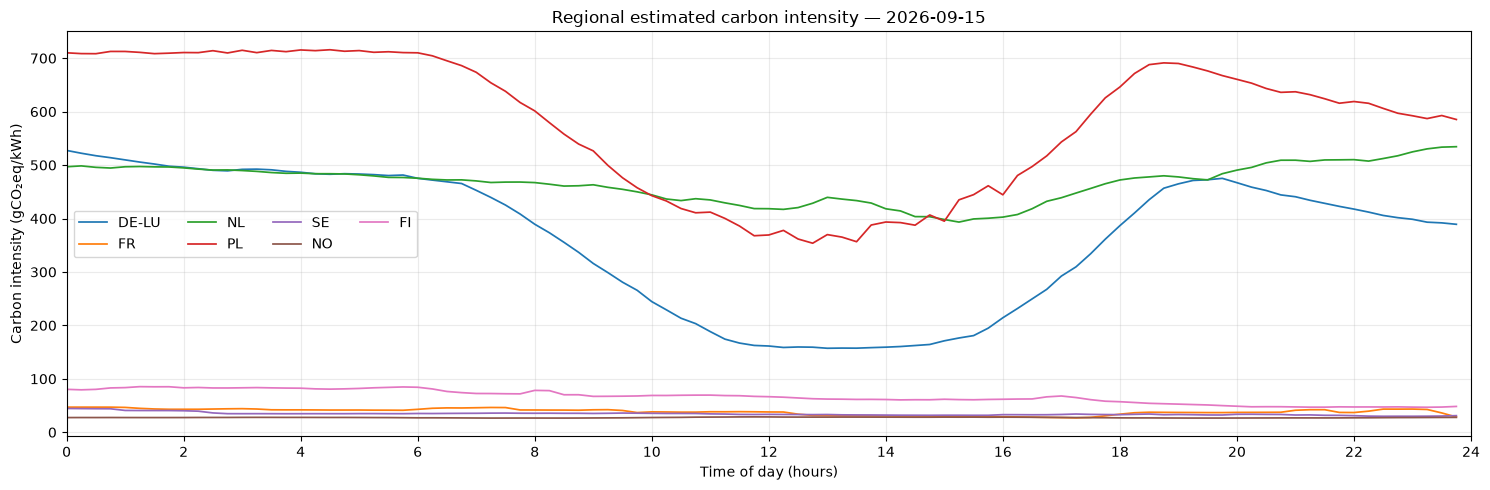

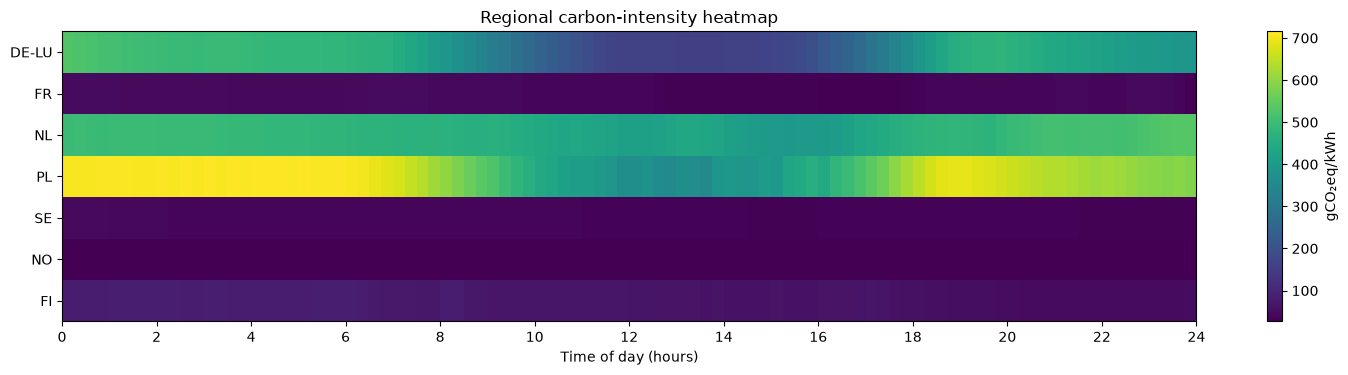

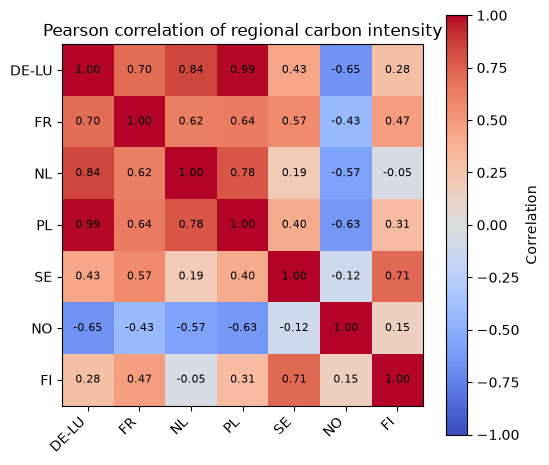

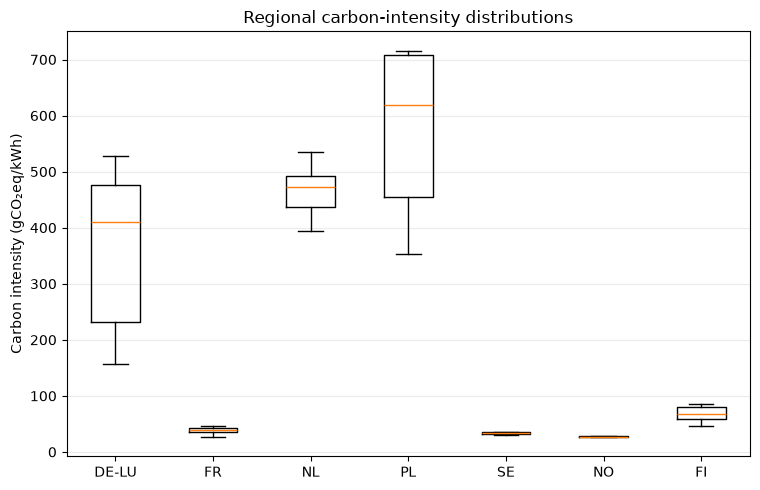

In [39]:
regional_stats = pd.DataFrame({
    "mean_gCO2eq_kWh": ci_day.mean(),
    "std_gCO2eq_kWh": ci_day.std(),
    "cv_pct": 100.0 * ci_day.std() / ci_day.mean(),
    "min_gCO2eq_kWh": ci_day.min(),
    "p05_gCO2eq_kWh": ci_day.quantile(0.05),
    "median_gCO2eq_kWh": ci_day.median(),
    "p95_gCO2eq_kWh": ci_day.quantile(0.95),
    "max_gCO2eq_kWh": ci_day.max(),
}).sort_values("mean_gCO2eq_kWh")

pearson_corr = ci_day.corr(method="pearson")
spearman_corr = ci_day.corr(method="spearman")

slot_mean_ci = ci_day.mean(axis=1)
slot_min_ci = ci_day.min(axis=1)
slot_max_ci = ci_day.max(axis=1)
spatial_spread = slot_max_ci - slot_min_ci

eda_opportunity = pd.Series({
    "mean_regional_CI": float(ci_day.to_numpy().mean()),
    "mean_best_region_CI": float(slot_min_ci.mean()),
    "mean_worst_region_CI": float(slot_max_ci.mean()),
    "mean_best_region_gap_gCO2eq_kWh": float((slot_mean_ci - slot_min_ci).mean()),
    "mean_cross_region_spread_gCO2eq_kWh": float(spatial_spread.mean()),
    "maximum_cross_region_spread_gCO2eq_kWh": float(spatial_spread.max()),
}, name="value")

display(regional_stats)
display(eda_opportunity.to_frame())
print("Pearson correlation:")
display(pearson_corr.round(3))
print("Spearman correlation:")
display(spearman_corr.round(3))

# Regional time series over the 24-hour arrival window.
plt.figure(figsize=(15, 5))
for region in ci_day.columns:
    plt.plot(slot_hours, ci_day[region], linewidth=1.25, label=region)
plt.title(f"Regional estimated carbon intensity — {DEMO_DATE}")
plt.xlabel("Time of day (hours)")
plt.ylabel("Carbon intensity (gCO₂eq/kWh)")
plt.xticks(np.arange(0, 24.1, 2))
plt.xlim(0, 24)
plt.grid(True, alpha=0.25)
plt.legend(ncol=min(4, len(ci_day.columns)))
plt.tight_layout()
plt.show()

# Region x time heatmap. Rows are regions; columns are 15-minute slots.
fig, ax = plt.subplots(figsize=(15, max(3.5, 0.55 * len(ci_day.columns))))
im = ax.imshow(
    ci_day.to_numpy(dtype=float).T,
    aspect="auto",
    interpolation="nearest",
    extent=[0, 24, len(ci_day.columns) - 0.5, -0.5],
)
ax.set_yticks(np.arange(len(ci_day.columns)))
ax.set_yticklabels(ci_day.columns)
ax.set_xticks(np.arange(0, 24.1, 2))
ax.set_xlabel("Time of day (hours)")
ax.set_title("Regional carbon-intensity heatmap")
fig.colorbar(im, ax=ax, label="gCO₂eq/kWh")
plt.tight_layout()
plt.show()

# Cross-region Pearson correlation heatmap.
fig, ax = plt.subplots(figsize=(max(5, 0.8 * len(ci_day.columns)), max(4, 0.7 * len(ci_day.columns))))
im = ax.imshow(pearson_corr.to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(ci_day.columns)))
ax.set_yticks(np.arange(len(ci_day.columns)))
ax.set_xticklabels(ci_day.columns, rotation=45, ha="right")
ax.set_yticklabels(ci_day.columns)
ax.set_title("Pearson correlation of regional carbon intensity")
for i in range(len(ci_day.columns)):
    for j in range(len(ci_day.columns)):
        ax.text(j, i, f"{pearson_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

# Distributional comparison.
plt.figure(figsize=(max(7, 1.1 * len(ci_day.columns)), 5))
plt.boxplot(
    [ci_day[r].to_numpy(dtype=float) for r in ci_day.columns],
    tick_labels=list(ci_day.columns),
    showfliers=False,
)
plt.title("Regional carbon-intensity distributions")
plt.ylabel("Carbon intensity (gCO₂eq/kWh)")
plt.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Data-center configuration

Each loaded region is represented by one data center. A data center has two explicit resource limits:

- `power_capacity_kw`: maximum aggregate power of concurrently executing jobs;
- `max_concurrent_jobs`: maximum number of simultaneous jobs.

The default values are placeholders. Set `DC_OVERRIDES` to represent heterogeneous regional capacities. Inter-region bandwidth can also be configured per directed origin-destination link.

In [40]:
regions = list(ci_day.columns)

dc_rows = []
for region in regions:
    override = DC_OVERRIDES.get(region, {})
    dc_rows.append({
        "region": region,
        "power_capacity_kw": float(
            override.get("power_capacity_kw", DEFAULT_DC_CAPACITY_KW)
        ),
        "max_concurrent_jobs": int(
            override.get("max_concurrent_jobs", DEFAULT_MAX_CONCURRENT_JOBS)
        ),
    })

dc_config = pd.DataFrame(dc_rows).set_index("region")

if (dc_config["power_capacity_kw"] <= 0).any():
    raise ValueError("Every data center must have positive power capacity.")
if (dc_config["max_concurrent_jobs"] < 1).any():
    raise ValueError("Every data center must allow at least one concurrent job.")

def link_bandwidth_gb_per_slot(origin, destination):
    if origin == destination:
        return np.inf
    return float(
        LINK_BANDWIDTH_OVERRIDES.get(
            (origin, destination),
            DEFAULT_LINK_BANDWIDTH_GB_PER_SLOT,
        )
    )

display(dc_config)
print("Directed network bandwidth defaults to "
      f"{DEFAULT_LINK_BANDWIDTH_GB_PER_SLOT:g} GB per 15-minute slot.")

,power_capacity_kw,max_concurrent_jobs
region,,
DE-LU,20.0000,4
FR,20.0000,4
NL,20.0000,4
PL,20.0000,4
SE,20.0000,4
NO,20.0000,4
FI,20.0000,4


Directed network bandwidth defaults to 100 GB per 15-minute slot.


## 6. Generate the 24-hour workload-arrival stream

Each synthetic job is described by:

- `release_slot`: arrival slot in `[0, 95]`;
- `home_region`: region where the job originates;
- `duration_slots`: fixed, non-preemptive execution duration;
- `power_kw`: constant IT power demand while running;
- `transfer_gb`: data/state volume that must be transferred if the job is dispatched outside its home region.

All jobs are spatially migratable to all configured regions in the demonstration. The origin region is retained to model migration energy. Arrival time is immutable: the scheduler must select a destination at that slot or report an admission/SLA failure. No policy is allowed to wait for a cleaner time interval.

Generated jobs: 450
Arrival slots covered: 96 / 96
Jobs by origin region:


,jobs,mean_power_kw,mean_duration_hours,total_transfer_gb
home_region,,,,
DE-LU,65,3.9308,0.9577,428.0000
FI,64,3.3125,0.8594,387.5000
FR,65,4.0385,0.8500,420.0000
NL,64,4.0781,0.8359,441.5000
NO,64,3.9453,0.9219,456.0000
PL,64,3.4922,0.7891,382.5000
SE,64,4.0156,0.8516,465.0000


,task_id,release_slot,arrival_hour,arrival_time,home_region,duration_slots,duration_hours,power_kw,transfer_gb,completion_slot,completion_time
0,J0057,0,0.0000,00:00,NO,8,2.0000,6.0000,10.0000,8,02:00
1,J0123,0,0.0000,00:00,DE-LU,8,2.0000,6.0000,5.0000,8,02:00
2,J0195,0,0.0000,00:00,NO,4,1.0000,6.0000,1.0000,4,01:00
3,J0196,0,0.0000,00:00,DE-LU,2,0.5000,2.0000,5.0000,2,00:30
4,J0251,0,0.0000,00:00,FI,4,1.0000,1.5000,20.0000,4,01:00
5,J0420,1,0.2500,00:15,NO,2,0.5000,8.0000,10.0000,3,00:45
6,J0140,1,0.2500,00:15,NL,4,1.0000,4.0000,1.0000,5,01:15
7,J0388,1,0.2500,00:15,PL,1,0.2500,3.0000,5.0000,2,00:30
8,J0151,1,0.2500,00:15,PL,2,0.5000,2.0000,20.0000,3,00:45
9,J0189,1,0.2500,00:15,DE-LU,2,0.5000,2.0000,1.0000,3,00:45


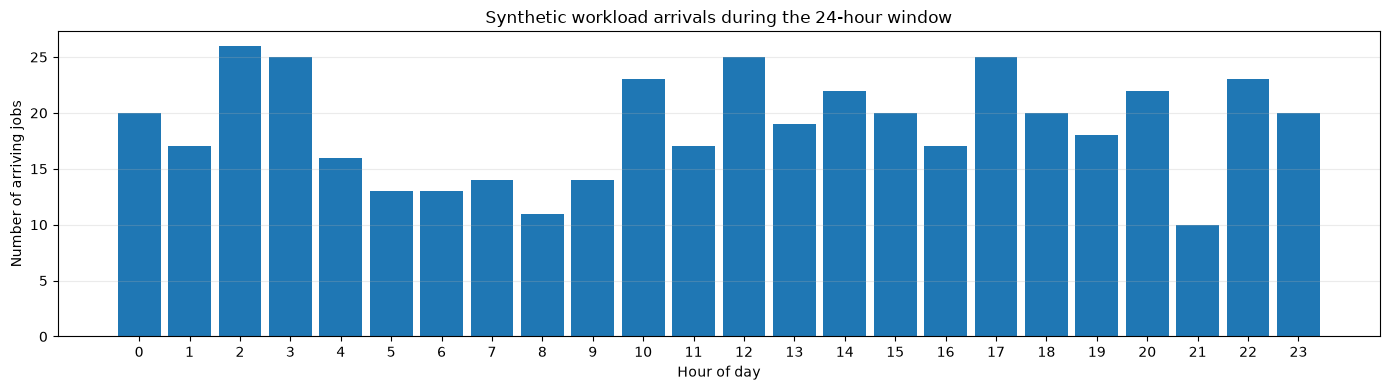

In [41]:
def slot_to_clock(slot):
    slot = int(slot)
    day_offset, slot_in_day = divmod(slot, SLOTS_PER_DAY)
    minutes = slot_in_day * 15
    clock = f"{minutes // 60:02d}:{minutes % 60:02d}"
    return clock if day_offset == 0 else f"{clock} (+{day_offset}d)"


def generate_workload(region_names, n_jobs=N_JOBS, seed=WORKLOAD_SEED):
    if len(region_names) < 1:
        raise ValueError("At least one home region is required.")
    if n_jobs < 1:
        raise ValueError("n_jobs must be positive.")

    rng = np.random.default_rng(seed)

    # Balanced origin-region population, shuffled to avoid region-specific task ordering.
    home_regions = np.resize(np.asarray(region_names, dtype=object), n_jobs)
    rng.shuffle(home_regions)

    release_slots = rng.integers(0, ARRIVAL_SLOTS, size=n_jobs, dtype=int)
    durations = rng.choice(
        DURATION_VALUES,
        size=n_jobs,
        p=DURATION_PROBABILITIES,
    ).astype(int)
    powers = rng.choice(
        POWER_VALUES_KW,
        size=n_jobs,
        p=POWER_PROBABILITIES,
    ).astype(float)
    transfer_gb = rng.choice(
        TRANSFER_SIZE_GB,
        size=n_jobs,
        p=TRANSFER_SIZE_PROBABILITIES,
    ).astype(float)

    jobs = pd.DataFrame({
        "task_id": [f"J{i + 1:04d}" for i in range(n_jobs)],
        "release_slot": release_slots,
        "arrival_hour": release_slots * SLOT_HOURS,
        "arrival_time": [slot_to_clock(s) for s in release_slots],
        "home_region": home_regions,
        "duration_slots": durations,
        "duration_hours": durations * SLOT_HOURS,
        "power_kw": powers,
        "transfer_gb": transfer_gb,
    })
    jobs["completion_slot"] = jobs["release_slot"] + jobs["duration_slots"]
    jobs["completion_time"] = jobs["completion_slot"].map(slot_to_clock)

    return jobs.sort_values(
        ["release_slot", "power_kw", "task_id"],
        ascending=[True, False, True],
    ).reset_index(drop=True)


tasks = generate_workload(regions, n_jobs=N_JOBS, seed=WORKLOAD_SEED)

print(f"Generated jobs: {len(tasks)}")
print(f"Arrival slots covered: {tasks['release_slot'].nunique()} / {ARRIVAL_SLOTS}")
print("Jobs by origin region:")
display(tasks.groupby("home_region").agg(
    jobs=("task_id", "count"),
    mean_power_kw=("power_kw", "mean"),
    mean_duration_hours=("duration_hours", "mean"),
    total_transfer_gb=("transfer_gb", "sum"),
))

display(tasks.head(12))

# Arrival intensity by 15-minute interval and by hour.
arrivals_per_slot = (
    tasks.groupby("release_slot").size()
    .reindex(range(ARRIVAL_SLOTS), fill_value=0)
)
arrivals_per_hour = arrivals_per_slot.to_numpy().reshape(24, SLOTS_PER_HOUR).sum(axis=1)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(np.arange(24), arrivals_per_hour, width=0.85)
ax.set_title("Synthetic workload arrivals during the 24-hour window")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Number of arriving jobs")
ax.set_xticks(np.arange(24))
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Spatial-only optimization model

Let \(J\) be the set of jobs, \(R\) the set of regions, \(a_j\) the fixed arrival slot, \(d_j\) the duration in slots, and \(p_j\) the constant power demand of job \(j\).

The binary decision variable is:

\[
x_{j,r} =
\begin{cases}
1, & \text{if job }j\text{ is dispatched to region }r,\\
0, & \text{otherwise.}
\end{cases}
\]

The start time is not a decision variable:

\[
s_j = a_j.
\]

For a job dispatched to region \(r\), compute emissions are:

\[
C^{\mathrm{comp}}_{j,r}
=
\frac{p_j\Delta t}{1000}
\sum_{t=a_j}^{a_j+d_j-1} CI_{r,t},
\]

where \(CI_{r,t}\) is in gCO₂e/kWh, \(p_j\) in kW, and \(\Delta t=0.25\) hours. The result is in kgCO₂e.

For a migrated job, the transfer-energy approximation is:

\[
E^{\mathrm{net}}_{j,r}
=
D_j\eta_{\mathrm{net}},\qquad r\ne h_j,
\]

where \(D_j\) is the transferred data volume in GB and \(\eta_{\mathrm{net}}\) is the assumed network energy in kWh/GB. Local placement has zero transfer energy.

The notebook approximates the carbon intensity of the transfer path by the mean of the origin and destination regional intensities at the arrival slot:

\[
CI^{\mathrm{net}}_{h_j,r,a_j}
=
\frac{CI_{h_j,a_j}+CI_{r,a_j}}{2}.
\]

Thus:

\[
C^{\mathrm{net}}_{j,r}
=
\frac{E^{\mathrm{net}}_{j,r}
CI^{\mathrm{net}}_{h_j,r,a_j}}{1000}.
\]

The spatial-only objective is:

\[
\min \sum_{j\in J}\sum_{r\in R}
\left(C^{\mathrm{comp}}_{j,r}+C^{\mathrm{net}}_{j,r}\right)x_{j,r}.
\]

Subject to:

**Single destination:**

\[
\sum_{r\in R}x_{j,r}=1,\quad \forall j.
\]

**Regional power capacity:**

\[
\sum_{j:\,a_j\le t<a_j+d_j}p_jx_{j,r}
\le P^{\max}_r,\quad \forall r,t.
\]

**Maximum concurrent jobs:**

\[
\sum_{j:\,a_j\le t<a_j+d_j}x_{j,r}
\le K^{\max}_r,\quad \forall r,t.
\]

**Directed network bandwidth at the arrival slot:**

\[
\sum_{j:\,h_j=o,\,a_j=t}D_jx_{j,r}
\le B_{o,r,t},\quad \forall o\ne r,t.
\]

**Binary assignment:**

\[
x_{j,r}\in\{0,1\}.
\]

This formulation assigns each job once at arrival and keeps it in that region until completion. It is therefore a spatial-only model; it does not perform temporal deferral or live migration during execution.

The network transfer is modeled as an energy/emissions overhead incurred in the arrival slot. Transfer completion delay, route-level network topology, and latency-based eligibility are not inferred from the supplied electricity datasets and should be added when measured network data are available.

## 8. Online dispatch policies

The online dispatcher processes jobs in arrival-slot order. Jobs arriving in the same 15-minute slot are handled as a batch with a deterministic largest-resource-demand-first tie-break (`power_kw × duration_slots`).

For each job, a candidate region is feasible only when:

1. the job's power fits the destination's per-slot residual power capacity for its entire runtime;
2. the destination's concurrent-job limit is respected for every occupied slot;
3. the origin-destination link has enough bandwidth in the arrival slot.

The **Greedy Spatial (compute + network)** policy scores every feasible destination using the full expected compute and transfer emissions of the job, then chooses the minimum. This is an online heuristic: it sees current workload arrivals and the available CI trace, but not the future arrivals that have not yet appeared.

In [42]:
def compute_emissions_kg(job, destination, ci_profile, network_kwh_per_gb):
    start = int(job.release_slot)
    end = start + int(job.duration_slots)
    power = float(job.power_kw)

    ci_values = ci_profile[destination][start:end]
    if not np.isfinite(ci_values).all():
        return np.inf

    compute_kg = power * SLOT_HOURS * float(np.sum(ci_values)) / 1000.0

    origin = str(job.home_region)
    if destination == origin:
        network_energy_kwh = 0.0
        network_kg = 0.0
    else:
        network_energy_kwh = float(job.transfer_gb) * float(network_kwh_per_gb)
        network_ci = 0.5 * (
            float(ci_profile[origin][start]) +
            float(ci_profile[destination][start])
        )
        network_kg = network_energy_kwh * network_ci / 1000.0

    return compute_kg + network_kg


def destination_is_feasible(
    job,
    destination,
    power_load,
    concurrency_load,
    link_load,
    dc_config,
):
    start = int(job.release_slot)
    end = start + int(job.duration_slots)
    power = float(job.power_kw)
    origin = str(job.home_region)

    cap_kw = float(dc_config.loc[destination, "power_capacity_kw"])
    max_jobs = int(dc_config.loc[destination, "max_concurrent_jobs"])

    if power > cap_kw + 1e-9:
        return False, "job_power_exceeds_region_capacity"

    if np.any(power_load[destination][start:end] + power > cap_kw + 1e-9):
        return False, "regional_power_capacity"

    if np.any(concurrency_load[destination][start:end] + 1 > max_jobs):
        return False, "regional_concurrency_limit"

    if destination != origin:
        link_key = (origin, destination, start)
        bandwidth = link_bandwidth_gb_per_slot(origin, destination)
        current = link_load.get(link_key, 0.0)
        if current + float(job.transfer_gb) > bandwidth + 1e-9:
            return False, "inter_region_bandwidth"

    return True, None


def run_online_dispatch(
    jobs,
    ci_profiles,
    dc_config,
    policy,
    network_kwh_per_gb=NETWORK_KWH_PER_GB,
):
    """
    policy:
      - 'local_only': home region only
      - 'home_first': home region first, then fixed region order
      - 'greedy_ci': minimum compute emissions, network ignored by selection
      - 'greedy_total': minimum compute + network emissions
    """
    if policy not in {"local_only", "home_first", "greedy_ci", "greedy_total"}:
        raise ValueError(f"Unknown dispatch policy: {policy}")

    region_names = list(ci_profiles.columns)
    power_load = {
        region: np.zeros(HORIZON_SLOTS, dtype=float)
        for region in region_names
    }
    concurrency_load = {
        region: np.zeros(HORIZON_SLOTS, dtype=int)
        for region in region_names
    }
    link_load = defaultdict(float)

    assignment_map = {}
    decision_rows = []
    rejected_rows = []

    ordered = jobs.copy()
    ordered["resource_demand"] = ordered["power_kw"] * ordered["duration_slots"]
    ordered = ordered.sort_values(
        ["release_slot", "resource_demand", "task_id"],
        ascending=[True, False, True],
    )

    # At each release slot, the scheduler chooses a destination and starts the job immediately.
    for row in ordered.itertuples(index=False):
        origin = str(row.home_region)

        if policy == "local_only":
            candidates = [origin]
        elif policy == "home_first":
            candidates = [origin] + [r for r in region_names if r != origin]
        else:
            candidates = region_names.copy()

        feasible = []
        rejected_reason_counts = defaultdict(int)

        for destination in candidates:
            ok, reason = destination_is_feasible(
                row,
                destination,
                power_load,
                concurrency_load,
                link_load,
                dc_config,
            )
            if not ok:
                rejected_reason_counts[reason] += 1
                continue

            # Compute-only emissions are used for the CI-only heuristic.
            compute_kg = compute_emissions_kg(
                row, destination, ci_profiles, network_kwh_per_gb=0.0
            )
            origin_ci = float(ci_profiles[origin][int(row.release_slot)])
            destination_ci = float(ci_profiles[destination][int(row.release_slot)])
            transfer_energy = (
                0.0 if destination == origin
                else float(row.transfer_gb) * float(network_kwh_per_gb)
            )
            transfer_ci = 0.5 * (origin_ci + destination_ci)
            network_kg = transfer_energy * transfer_ci / 1000.0
            total_kg = compute_kg + network_kg

            feasible.append({
                "destination": destination,
                "compute_kg": compute_kg,
                "network_energy_kwh": transfer_energy,
                "network_kg": network_kg,
                "total_kg": total_kg,
            })

            if policy in {"local_only", "home_first"}:
                # Deterministic first-feasible placement, independent of carbon intensity.
                break

        if not feasible:
            rejected_rows.append({
                "task_id": str(row.task_id),
                "release_slot": int(row.release_slot),
                "home_region": origin,
                "failure_reason": (
                    "no_feasible_destination: " +
                    ", ".join(f"{k}={v}" for k, v in rejected_reason_counts.items())
                ),
            })
            continue

        if policy == "greedy_ci":
            chosen = min(feasible, key=lambda x: (
                x["compute_kg"], x["destination"]
            ))
        elif policy == "greedy_total":
            chosen = min(feasible, key=lambda x: (
                x["total_kg"], x["destination"]
            ))
        else:
            chosen = feasible[0]

        destination = chosen["destination"]
        start = int(row.release_slot)
        end = start + int(row.duration_slots)

        assignment_map[str(row.task_id)] = destination
        power_load[destination][start:end] += float(row.power_kw)
        concurrency_load[destination][start:end] += 1

        if destination != origin:
            link_load[(origin, destination, start)] += float(row.transfer_gb)

        decision_rows.append({
            "task_id": str(row.task_id),
            "release_slot": start,
            "arrival_time": slot_to_clock(start),
            "home_region": origin,
            "assigned_region": destination,
            "duration_slots": int(row.duration_slots),
            "duration_hours": float(row.duration_hours),
            "power_kw": float(row.power_kw),
            "transfer_gb": float(row.transfer_gb),
            "migrated": destination != origin,
            "compute_emissions_kg": chosen["compute_kg"],
            "network_energy_kwh": chosen["network_energy_kwh"],
            "network_emissions_kg": chosen["network_kg"],
            "total_emissions_kg": chosen["total_kg"],
        })

    return (
        assignment_map,
        pd.DataFrame(decision_rows),
        pd.DataFrame(rejected_rows),
    )


policy_definitions = {
    "Local-only": "local_only",
    "Home-first / carbon-unaware": "home_first",
    "Greedy Spatial (CI-only)": "greedy_ci",
    "Greedy Spatial (compute + network)": "greedy_total",
}

online_assignment_maps = {}
online_decisions = {}
online_rejections = {}

for label, policy_code in policy_definitions.items():
    assignment_map, decisions, rejected = run_online_dispatch(
        tasks, ci_execution, dc_config, policy_code
    )
    online_assignment_maps[label] = assignment_map
    online_decisions[label] = decisions
    online_rejections[label] = rejected

online_admission_summary = pd.DataFrame([
    {
        "policy": label,
        "generated_jobs": len(tasks),
        "scheduled_jobs": len(online_assignment_maps[label]),
        "rejected_jobs": len(online_rejections[label]),
        "admission_rate_pct": 100.0 * len(online_assignment_maps[label]) / len(tasks),
        "SLA_violation_rate_pct": 100.0 * len(online_rejections[label]) / len(tasks),
        "migrated_jobs": int(online_decisions[label]["migrated"].sum()) if not online_decisions[label].empty else 0,
    }
    for label in policy_definitions
]).set_index("policy")

display(online_admission_summary)

,generated_jobs,scheduled_jobs,rejected_jobs,admission_rate_pct,SLA_violation_rate_pct,migrated_jobs
policy,,,,,,
Local-only,450,404,46,89.7778,10.2222,0
Home-first / carbon-unaware,450,450,0,100.0000,0.0000,60
Greedy Spatial (CI-only),450,450,0,100.0000,0.0000,387
Greedy Spatial (compute + network),450,450,0,100.0000,0.0000,385


## 9. Offline MILP benchmark: joint destination assignment at fixed arrival times

The MILP assigns each job to exactly one region. Arrival time and duration are parameters, not decision variables. It therefore evaluates the best spatial placement for the known 24-hour workload under regional power, concurrency, and link-bandwidth constraints.

Because the model sees the entire day's job set before assigning destinations, it is a **retrospective spatial oracle**. It is useful as an optimization benchmark, but should not be described as an online policy.

In [43]:
def optimize_spatial_milp(
    jobs,
    ci_profiles,
    dc_config,
    network_kwh_per_gb=NETWORK_KWH_PER_GB,
    time_limit_seconds=MILP_TIME_LIMIT_SECONDS,
    relative_gap=MILP_RELATIVE_GAP,
):
    jobs = jobs.reset_index(drop=True).copy()
    region_names = list(ci_profiles.columns)
    n_jobs = len(jobs)
    n_regions = len(region_names)

    # Candidate binary variables: one (job, destination-region) pair.
    candidates = []
    objective = []
    for j, row in jobs.iterrows():
        origin = str(row["home_region"])
        start = int(row["release_slot"])
        end = start + int(row["duration_slots"])
        for region in region_names:
            if float(row["power_kw"]) > float(dc_config.loc[region, "power_capacity_kw"]) + 1e-9:
                continue
            if end > len(ci_profiles):
                continue

            compute_kg = compute_emissions_kg(
                row, region, ci_profiles, network_kwh_per_gb=0.0
            )
            if not np.isfinite(compute_kg):
                continue

            if region == origin:
                network_kg = 0.0
            else:
                transfer_energy = float(row["transfer_gb"]) * network_kwh_per_gb
                network_ci = 0.5 * (
                    float(ci_profiles[origin][start]) +
                    float(ci_profiles[region][start])
                )
                network_kg = transfer_energy * network_ci / 1000.0

            candidates.append((j, region))
            objective.append(compute_kg + network_kg)

    if not candidates:
        raise RuntimeError("MILP has no feasible job-region assignment variables.")

    candidate_by_job = defaultdict(list)
    for k, (j, region) in enumerate(candidates):
        candidate_by_job[j].append(k)

    jobs_without_candidates = [
        str(jobs.iloc[j]["task_id"])
        for j in range(n_jobs)
        if not candidate_by_job[j]
    ]
    if jobs_without_candidates:
        raise RuntimeError(
            "No individual destination is feasible for jobs: "
            + ", ".join(jobs_without_candidates[:10])
        )

    # Constraint row layout: job assignment, regional power, regional concurrency,
    # and directed-link bandwidth in each arrival slot.
    power_start = n_jobs
    concurrency_start = power_start + n_regions * HORIZON_SLOTS

    bandwidth_keys = sorted({
        (str(jobs.iloc[j]["home_region"]), region, int(jobs.iloc[j]["release_slot"]))
        for j, region in candidates
        if region != str(jobs.iloc[j]["home_region"])
    })
    bandwidth_row = {
        key: concurrency_start + n_regions * HORIZON_SLOTS + i
        for i, key in enumerate(bandwidth_keys)
    }
    n_constraints = concurrency_start + n_regions * HORIZON_SLOTS + len(bandwidth_keys)

    def power_row(region_index, slot):
        return power_start + region_index * HORIZON_SLOTS + slot

    def concurrency_row(region_index, slot):
        return concurrency_start + region_index * HORIZON_SLOTS + slot

    region_index = {region: i for i, region in enumerate(region_names)}

    row_indices = []
    col_indices = []
    values = []

    for k, (j, region) in enumerate(candidates):
        row = jobs.iloc[j]
        origin = str(row["home_region"])
        start = int(row["release_slot"])
        end = start + int(row["duration_slots"])
        power = float(row["power_kw"])
        r_idx = region_index[region]

        # Each job is assigned once.
        row_indices.append(j)
        col_indices.append(k)
        values.append(1.0)

        # Resource consumption is reserved for all execution slots.
        for slot in range(start, end):
            row_indices.append(power_row(r_idx, slot))
            col_indices.append(k)
            values.append(power)

            row_indices.append(concurrency_row(r_idx, slot))
            col_indices.append(k)
            values.append(1.0)

        # Transfer bandwidth is consumed at arrival.
        if region != origin:
            key = (origin, region, start)
            row_indices.append(bandwidth_row[key])
            col_indices.append(k)
            values.append(float(row["transfer_gb"]))

    constraint_matrix = coo_matrix(
        (values, (row_indices, col_indices)),
        shape=(n_constraints, len(candidates)),
        dtype=float,
    ).tocsr()

    lower = np.full(n_constraints, -np.inf, dtype=float)
    upper = np.full(n_constraints, np.inf, dtype=float)

    # Assignment equality.
    lower[:n_jobs] = 1.0
    upper[:n_jobs] = 1.0

    # Regional power and concurrency ceilings.
    for region, r_idx in region_index.items():
        capacity = float(dc_config.loc[region, "power_capacity_kw"])
        max_jobs = int(dc_config.loc[region, "max_concurrent_jobs"])
        for slot in range(HORIZON_SLOTS):
            upper[power_row(r_idx, slot)] = capacity
            upper[concurrency_row(r_idx, slot)] = max_jobs

    # Directed network bandwidth constraints.
    for key, row_id in bandwidth_row.items():
        origin, destination, arrival_slot = key
        upper[row_id] = link_bandwidth_gb_per_slot(origin, destination)

    result = milp(
        c=np.asarray(objective, dtype=float),
        integrality=np.ones(len(candidates), dtype=np.int8),
        bounds=Bounds(np.zeros(len(candidates)), np.ones(len(candidates))),
        constraints=LinearConstraint(constraint_matrix, lower, upper),
        options={
            "time_limit": float(time_limit_seconds),
            "mip_rel_gap": float(relative_gap),
            "presolve": True,
        },
    )

    if result.x is None:
        raise RuntimeError(
            f"Spatial MILP returned no feasible incumbent. "
            f"Status={result.status}; message={result.message}. "
            "Increase capacities/bandwidth, reduce workload intensity, or increase the time limit."
        )

    selected = np.flatnonzero(result.x > 0.5)
    if len(selected) != n_jobs:
        raise RuntimeError(
            f"MILP selected {len(selected)} of {n_jobs} jobs. "
            "The assignment solution is incomplete."
        )

    assignment_map = {
        str(jobs.iloc[candidates[k][0]]["task_id"]): candidates[k][1]
        for k in selected
    }

    solver_info = {
        "status": int(result.status),
        "success_optimality_proven": bool(result.success),
        "message": str(result.message),
        "objective_kgCO2eq": float(result.fun),
        "mip_gap": float(getattr(result, "mip_gap", np.nan)),
        "candidate_variables": len(candidates),
        "jobs": n_jobs,
    }
    return assignment_map, solver_info


if len(regions) >= 2:
    milp_assignment_map, milp_solver_info = optimize_spatial_milp(
        tasks, ci_execution, dc_config
    )
    print("MILP solver information:")
    display(pd.Series(milp_solver_info, name="value").to_frame())
    online_assignment_maps["MILP spatial oracle"] = milp_assignment_map
else:
    milp_assignment_map = online_assignment_maps["Greedy Spatial (compute + network)"]
    milp_solver_info = {
        "status": None,
        "success_optimality_proven": False,
        "message": "Skipped: at least two regions are required for a spatial benchmark.",
        "objective_kgCO2eq": np.nan,
        "mip_gap": np.nan,
        "candidate_variables": 0,
        "jobs": len(tasks),
    }
    print(milp_solver_info["message"])

MILP solver information:


,value
status,0
success_optimality_proven,True
message,Optimization terminated successfully. (HiGHS S...
objective_kgCO2eq,92.6209
mip_gap,0.0041
candidate_variables,3150
jobs,450


## 10. Evaluate emissions, resource utilization, migration, and SLA outcomes

For each policy, evaluation recalculates compute energy/emissions in the assigned destination and network energy/emissions for migrated jobs. Capacity and concurrency are checked across the full execution horizon, including the short post-midnight tail.

In this immediate-dispatch model, jobs are never intentionally deferred. A job that cannot be placed in any eligible data center at its arrival time is counted as rejected and as an SLA violation. For accepted jobs, completion occurs after the fixed runtime; there is no separate deadline-waiting variable.

In [44]:
def evaluate_assignment_map(
    jobs,
    assignment_map,
    ci_profiles,
    dc_config,
    network_kwh_per_gb=NETWORK_KWH_PER_GB,
):
    regions = list(ci_profiles.columns)
    power_load = {r: np.zeros(HORIZON_SLOTS, dtype=float) for r in regions}
    concurrency_load = {r: np.zeros(HORIZON_SLOTS, dtype=int) for r in regions}
    link_load = defaultdict(float)

    assignment_rows = []
    compute_energy_kwh = 0.0
    compute_emissions_kg = 0.0
    network_energy_kwh = 0.0
    network_emissions_kg = 0.0

    task_lookup = jobs.set_index("task_id")

    for task_id, destination in assignment_map.items():
        row = task_lookup.loc[task_id]
        origin = str(row["home_region"])
        destination = str(destination)
        start = int(row["release_slot"])
        end = start + int(row["duration_slots"])
        power = float(row["power_kw"])
        duration = int(row["duration_slots"])

        if destination not in regions:
            raise ValueError(f"Unknown destination {destination} for task {task_id}.")
        if start < 0 or end > HORIZON_SLOTS:
            raise ValueError(f"Task {task_id} exceeds the execution accounting horizon.")

        ci_values = ci_profiles[destination][start:end]
        if not np.isfinite(ci_values).all():
            raise ValueError(f"Task {task_id} overlaps missing CI data in {destination}.")

        task_energy = power * duration * SLOT_HOURS
        task_compute_kg = power * SLOT_HOURS * float(np.sum(ci_values)) / 1000.0

        if destination == origin:
            task_network_energy = 0.0
            task_network_kg = 0.0
        else:
            task_network_energy = float(row["transfer_gb"]) * network_kwh_per_gb
            network_ci = 0.5 * (
                float(ci_profiles[origin][start]) +
                float(ci_profiles[destination][start])
            )
            task_network_kg = task_network_energy * network_ci / 1000.0
            link_load[(origin, destination, start)] += float(row["transfer_gb"])

        compute_energy_kwh += task_energy
        compute_emissions_kg += task_compute_kg
        network_energy_kwh += task_network_energy
        network_emissions_kg += task_network_kg

        power_load[destination][start:end] += power
        concurrency_load[destination][start:end] += 1

        assignment_rows.append({
            "task_id": task_id,
            "home_region": origin,
            "assigned_region": destination,
            "release_slot": start,
            "arrival_time": slot_to_clock(start),
            "completion_slot": end,
            "completion_time": slot_to_clock(end),
            "duration_slots": duration,
            "duration_hours": duration * SLOT_HOURS,
            "power_kw": power,
            "transfer_gb": float(row["transfer_gb"]),
            "migrated": destination != origin,
            "compute_energy_kwh": task_energy,
            "compute_emissions_kg": task_compute_kg,
            "network_energy_kwh": task_network_energy,
            "network_emissions_kg": task_network_kg,
            "total_emissions_kg": task_compute_kg + task_network_kg,
        })

    assignment_table = pd.DataFrame(assignment_rows)
    rejected_jobs = len(jobs) - len(assignment_map)
    total_emissions = compute_emissions_kg + network_emissions_kg
    total_energy = compute_energy_kwh + network_energy_kwh

    power_violation_slots = 0
    concurrency_violation_slots = 0
    regional_utilization_rows = []

    for region in regions:
        capacity = float(dc_config.loc[region, "power_capacity_kw"])
        max_jobs = int(dc_config.loc[region, "max_concurrent_jobs"])
        power_violation_slots += int(np.sum(power_load[region] > capacity + 1e-8))
        concurrency_violation_slots += int(np.sum(concurrency_load[region] > max_jobs))
        regional_utilization_rows.append({
            "region": region,
            "capacity_kw": capacity,
            "max_concurrent_jobs": max_jobs,
            "mean_power_kw": float(power_load[region].mean()),
            "peak_power_kw": float(power_load[region].max(initial=0.0)),
            "mean_capacity_utilization_pct": (
                100.0 * float(power_load[region].mean()) / capacity
            ),
            "peak_capacity_utilization_pct": (
                100.0 * float(power_load[region].max(initial=0.0)) / capacity
            ),
            "peak_concurrent_jobs": int(concurrency_load[region].max(initial=0)),
        })

    bandwidth_violations = 0
    for (origin, destination, slot), transferred_gb in link_load.items():
        bandwidth = link_bandwidth_gb_per_slot(origin, destination)
        bandwidth_violations += int(transferred_gb > bandwidth + 1e-8)

    scheduled_jobs = len(assignment_map)
    migrated_jobs = (
        int(assignment_table["migrated"].sum()) if not assignment_table.empty else 0
    )
    total_emissions = compute_emissions_kg + network_emissions_kg

    metrics = {
        "generated_jobs": len(jobs),
        "scheduled_jobs": scheduled_jobs,
        "rejected_jobs": rejected_jobs,
        "admission_rate_pct": 100.0 * scheduled_jobs / len(jobs) if len(jobs) else np.nan,
        "SLA_violation_rate_pct": 100.0 * rejected_jobs / len(jobs) if len(jobs) else np.nan,
        "migrated_jobs": migrated_jobs,
        "migration_rate_pct": 100.0 * migrated_jobs / scheduled_jobs if scheduled_jobs else 0.0,
        "transferred_data_gb": float(assignment_table.loc[assignment_table["migrated"], "transfer_gb"].sum()) if migrated_jobs else 0.0,
        "compute_energy_kwh": compute_energy_kwh,
        "network_energy_kwh": network_energy_kwh,
        "total_energy_kwh": total_energy,
        "compute_emissions_kgCO2eq": compute_emissions_kg,
        "network_emissions_kgCO2eq": network_emissions_kg,
        "total_emissions_kgCO2eq": total_emissions,
        "network_emissions_share_pct": (
            100.0 * network_emissions_kg / total_emissions if total_emissions else 0.0
        ),
        "average_network_energy_per_migrated_job_kwh": (
            network_energy_kwh / migrated_jobs if migrated_jobs else 0.0
        ),
        "average_network_emissions_per_migrated_job_kg": (
            network_emissions_kg / migrated_jobs if migrated_jobs else 0.0
        ),
        "power_capacity_violation_slots": power_violation_slots,
        "concurrency_violation_slots": concurrency_violation_slots,
        "bandwidth_violation_events": bandwidth_violations,
        "peak_power_kw_system": max(
            (float(power_load[r].max(initial=0.0)) for r in regions),
            default=0.0,
        ),
        "peak_concurrent_jobs_system": max(
            (int(concurrency_load[r].max(initial=0)) for r in regions),
            default=0,
        ),
        "mean_capacity_utilization_pct_all_regions": float(np.mean([
            x["mean_capacity_utilization_pct"] for x in regional_utilization_rows
        ])),
        "peak_capacity_utilization_pct_any_region": max([
            x["peak_capacity_utilization_pct"] for x in regional_utilization_rows
        ], default=0.0),
    }

    regional_utilization = pd.DataFrame(regional_utilization_rows).set_index("region")

    if power_violation_slots or concurrency_violation_slots or bandwidth_violations:
        raise AssertionError(
            "A capacity-feasible policy produced resource violations: "
            f"power={power_violation_slots}, concurrency={concurrency_violation_slots}, "
            f"bandwidth={bandwidth_violations}."
        )

    return metrics, assignment_table, power_load, concurrency_load, regional_utilization


policy_metrics = {}
policy_schedules = {}
policy_power_loads = {}
policy_concurrency_loads = {}
regional_utilization_by_policy = {}

for policy_name, assignment_map in online_assignment_maps.items():
    outputs = evaluate_assignment_map(
        tasks, assignment_map, ci_execution, dc_config
    )
    (
        policy_metrics[policy_name],
        policy_schedules[policy_name],
        policy_power_loads[policy_name],
        policy_concurrency_loads[policy_name],
        regional_utilization_by_policy[policy_name],
    ) = outputs

metrics_table = pd.DataFrame(policy_metrics).T
display(metrics_table[[
    "generated_jobs", "scheduled_jobs", "rejected_jobs", "admission_rate_pct",
    "SLA_violation_rate_pct", "migrated_jobs", "migration_rate_pct",
    "compute_energy_kwh", "network_energy_kwh",
    "compute_emissions_kgCO2eq", "network_emissions_kgCO2eq",
    "total_emissions_kgCO2eq", "network_emissions_share_pct",
    "mean_capacity_utilization_pct_all_regions",
    "peak_capacity_utilization_pct_any_region",
]])

,generated_jobs,scheduled_jobs,rejected_jobs,admission_rate_pct,SLA_violation_rate_pct,migrated_jobs,migration_rate_pct,compute_energy_kwh,network_energy_kwh,compute_emissions_kgCO2eq,network_emissions_kgCO2eq,total_emissions_kgCO2eq,network_emissions_share_pct,mean_capacity_utilization_pct_all_regions,peak_capacity_utilization_pct_any_region
Local-only,450.0000,404.0000,46.0000,89.7778,10.2222,0.0000,0.0000,"1,396.1250",0.0000,308.6543,0.0000,308.6543,0.0000,38.3551,100.0000
Home-first / carbon-unaware,450.0000,450.0000,0.0000,100.0000,0.0000,60.0000,13.3333,"1,511.2500",4.0900,340.1046,1.1136,341.2182,0.3264,41.5179,100.0000
Greedy Spatial (CI-only),450.0000,450.0000,0.0000,100.0000,0.0000,387.0000,86.0000,"1,511.2500",25.6550,100.3960,4.4011,104.7971,4.1997,41.5179,100.0000
Greedy Spatial (compute + network),450.0000,450.0000,0.0000,100.0000,0.0000,385.0000,85.5556,"1,511.2500",25.4050,100.4066,4.2759,104.6825,4.0846,41.5179,100.0000
MILP spatial oracle,450.0000,450.0000,0.0000,100.0000,0.0000,360.0000,80.0000,"1,511.2500",22.3850,88.7419,3.8790,92.6209,4.1880,41.5179,100.0000


## 11. Carbon-savings calculation and common-workload comparison

The primary operational baseline is `Home-first / carbon-unaware`. For a fair emissions comparison, each policy is compared on the **same jobs accepted by both that policy and the baseline**. This prevents a policy from appearing cleaner merely because it rejected more workload.

\[
\mathrm{Savings}_{kg}
=
C_{\mathrm{baseline,common}}-C_{\mathrm{policy,common}}
\]

\[
\mathrm{Savings}_{\%}
=
100\cdot
\frac{C_{\mathrm{baseline,common}}-C_{\mathrm{policy,common}}}
{C_{\mathrm{baseline,common}}}.
\]

The full admission rate and SLA violation rate are reported separately. The unshifted `Local-only` case is also retained as a direct same-region carbon reference; it may reject jobs if the origin data center reaches its capacity or concurrency limit.

In [45]:
def emissions_for_job_subset(jobs, assignment_map, selected_ids, ci_profiles, network_kwh_per_gb):
    lookup = jobs.set_index("task_id")
    total_kg = 0.0
    compute_kg = 0.0
    network_kg = 0.0

    for task_id in selected_ids:
        destination = assignment_map[task_id]
        row = lookup.loc[task_id]
        origin = str(row["home_region"])
        start = int(row["release_slot"])
        end = start + int(row["duration_slots"])
        power = float(row["power_kw"])

        task_compute = (
            power * SLOT_HOURS *
            float(np.sum(ci_profiles[destination][start:end])) / 1000.0
        )
        if destination == origin:
            task_network = 0.0
        else:
            network_energy = float(row["transfer_gb"]) * network_kwh_per_gb
            network_ci = 0.5 * (
                float(ci_profiles[origin][start]) +
                float(ci_profiles[destination][start])
            )
            task_network = network_energy * network_ci / 1000.0

        compute_kg += task_compute
        network_kg += task_network
        total_kg += task_compute + task_network

    return {
        "compute_emissions_kgCO2eq": compute_kg,
        "network_emissions_kgCO2eq": network_kg,
        "total_emissions_kgCO2eq": total_kg,
    }


PRIMARY_BASELINE = "Home-first / carbon-unaware"
baseline_map = online_assignment_maps[PRIMARY_BASELINE]
baseline_accepted_ids = set(baseline_map)

savings_rows = []
for policy_name, assignment_map in online_assignment_maps.items():
    common_ids = sorted(baseline_accepted_ids & set(assignment_map))
    if not common_ids:
        savings_rows.append({
            "policy": policy_name,
            "common_jobs": 0,
            "baseline_emissions_kg": np.nan,
            "policy_emissions_kg": np.nan,
            "carbon_savings_kg": np.nan,
            "carbon_savings_pct": np.nan,
        })
        continue

    baseline_common = emissions_for_job_subset(
        tasks, baseline_map, common_ids, ci_execution, NETWORK_KWH_PER_GB
    )
    policy_common = emissions_for_job_subset(
        tasks, assignment_map, common_ids, ci_execution, NETWORK_KWH_PER_GB
    )
    base_kg = baseline_common["total_emissions_kgCO2eq"]
    policy_kg = policy_common["total_emissions_kgCO2eq"]

    savings_rows.append({
        "policy": policy_name,
        "common_jobs": len(common_ids),
        "baseline_emissions_kg": base_kg,
        "policy_emissions_kg": policy_kg,
        "carbon_savings_kg": base_kg - policy_kg,
        "carbon_savings_pct": (
            100.0 * (base_kg - policy_kg) / base_kg if base_kg > 0 else np.nan
        ),
        "baseline_compute_emissions_kg": baseline_common["compute_emissions_kgCO2eq"],
        "policy_compute_emissions_kg": policy_common["compute_emissions_kgCO2eq"],
        "policy_network_emissions_kg": policy_common["network_emissions_kgCO2eq"],
    })

savings_table = pd.DataFrame(savings_rows).set_index("policy")
display(savings_table)

print(
    "Primary baseline: Home-first / carbon-unaware. "
    "Savings are computed on the common accepted job set; admission and SLA metrics "
    "remain based on the full generated workload."
)

,common_jobs,baseline_emissions_kg,policy_emissions_kg,carbon_savings_kg,carbon_savings_pct,baseline_compute_emissions_kg,policy_compute_emissions_kg,policy_network_emissions_kg
policy,,,,,,,,
Local-only,404,306.3492,308.6543,-2.3052,-0.7525,305.9147,308.6543,0.0000
Home-first / carbon-unaware,450,341.2182,341.2182,0.0000,0.0000,340.1046,340.1046,1.1136
Greedy Spatial (CI-only),450,341.2182,104.7971,236.4211,69.2874,340.1046,100.3960,4.4011
Greedy Spatial (compute + network),450,341.2182,104.6825,236.5357,69.3210,340.1046,100.4066,4.2759
MILP spatial oracle,450,341.2182,92.6209,248.5973,72.8558,340.1046,88.7419,3.8790


Primary baseline: Home-first / carbon-unaware. Savings are computed on the common accepted job set; admission and SLA metrics remain based on the full generated workload.


## 12. Validate the dispatch decisions

The following checks verify that:

- every accepted job starts in its arrival slot;
- every job has exactly one destination;
- the assigned region is a configured data center;
- power, concurrency, and bandwidth constraints are satisfied;
- no task is deferred or preempted.

In [46]:
for policy_name, assignment_map in online_assignment_maps.items():
    schedule = policy_schedules[policy_name]
    if len(schedule) != len(assignment_map):
        raise AssertionError(f"{policy_name}: assignment count mismatch.")
    if not schedule.empty:
        assert (schedule["release_slot"] >= 0).all()
        assert (schedule["release_slot"] < ARRIVAL_SLOTS).all()
        assert (schedule["completion_slot"] > schedule["release_slot"]).all()
        assert (schedule["assigned_region"].isin(regions)).all()

        # Since this is spatial-only, start_slot must equal release_slot.
        assert (
            schedule["completion_slot"] -
            schedule["duration_slots"] ==
            schedule["release_slot"]
        ).all()

    m = policy_metrics[policy_name]
    assert m["power_capacity_violation_slots"] == 0
    assert m["concurrency_violation_slots"] == 0
    assert m["bandwidth_violation_events"] == 0

print("Validation passed: accepted jobs start at arrival and all resource constraints hold.")

Validation passed: accepted jobs start at arrival and all resource constraints hold.


## 13. Visualize the spatial allocation

The plots connect regional grid conditions with the scheduler's decisions:

1. regional carbon-intensity profiles over 24 hours;
2. destination-region workload power over time;
3. per-job placement Gantt chart;
4. origin-destination migration matrix;
5. regional capacity utilization;
6. emissions decomposition and carbon savings.

The Gantt chart includes the execution tail after midnight. The arrival process itself remains limited to the selected 24-hour day.

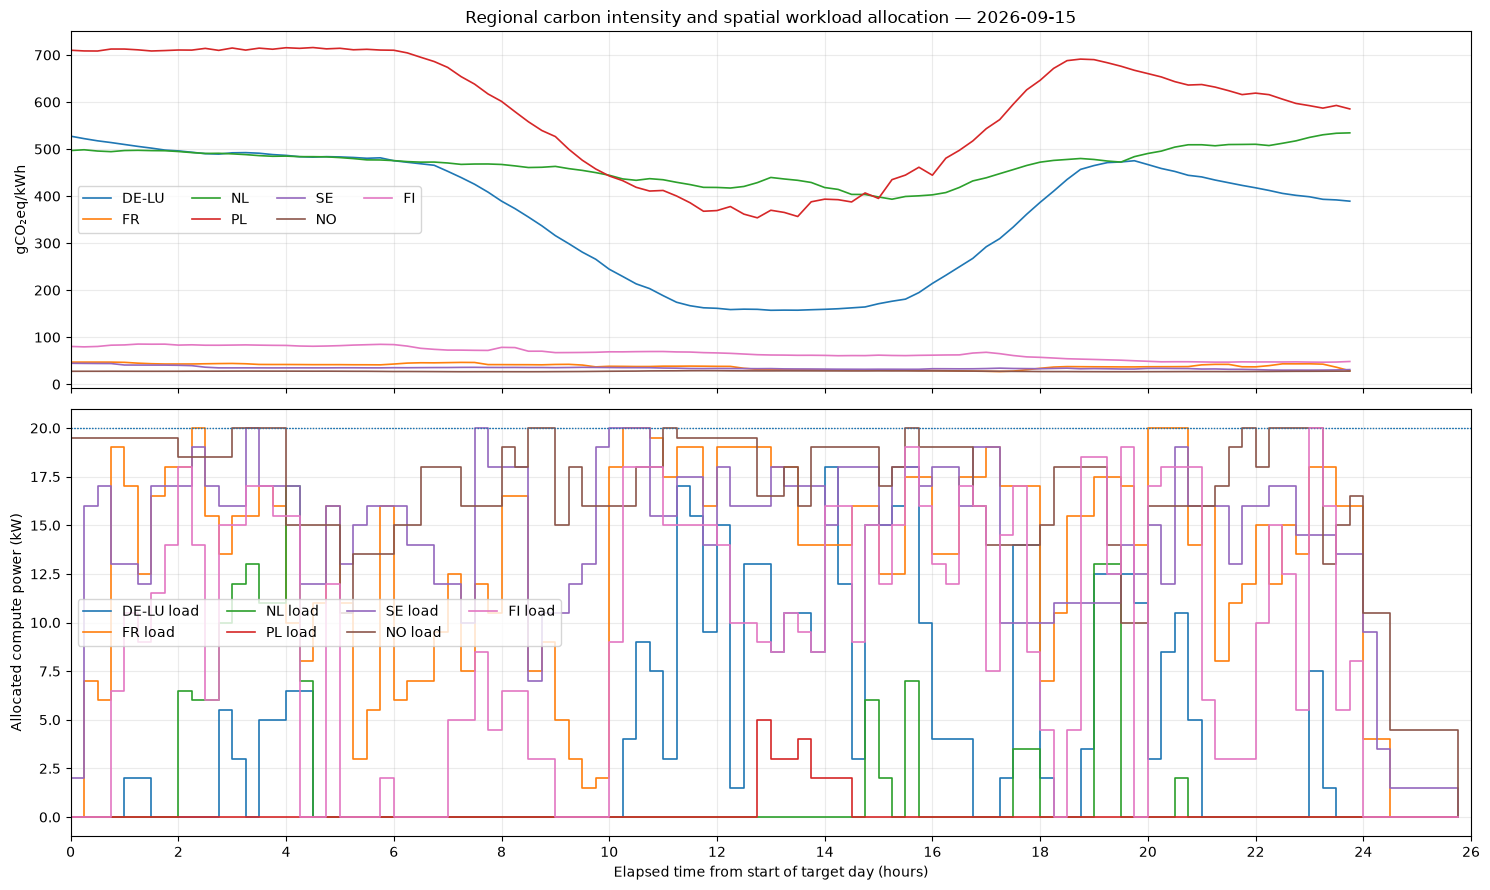

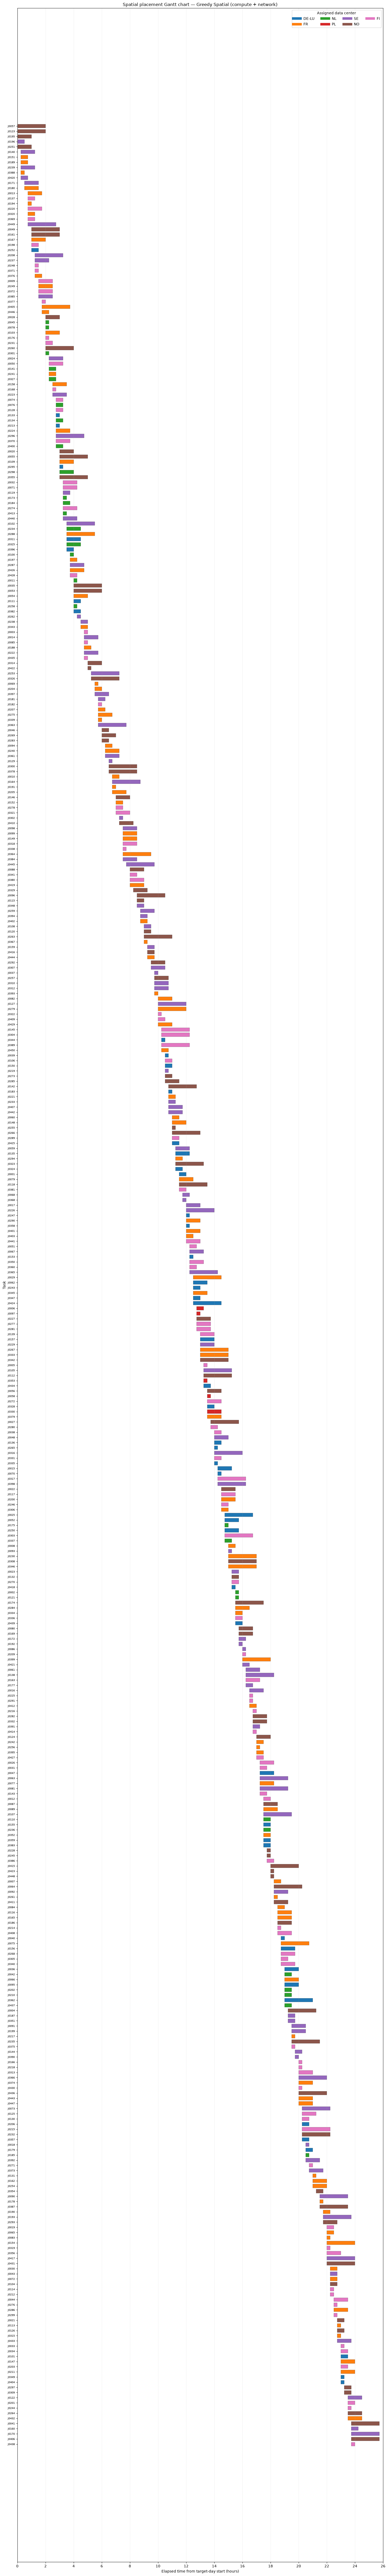

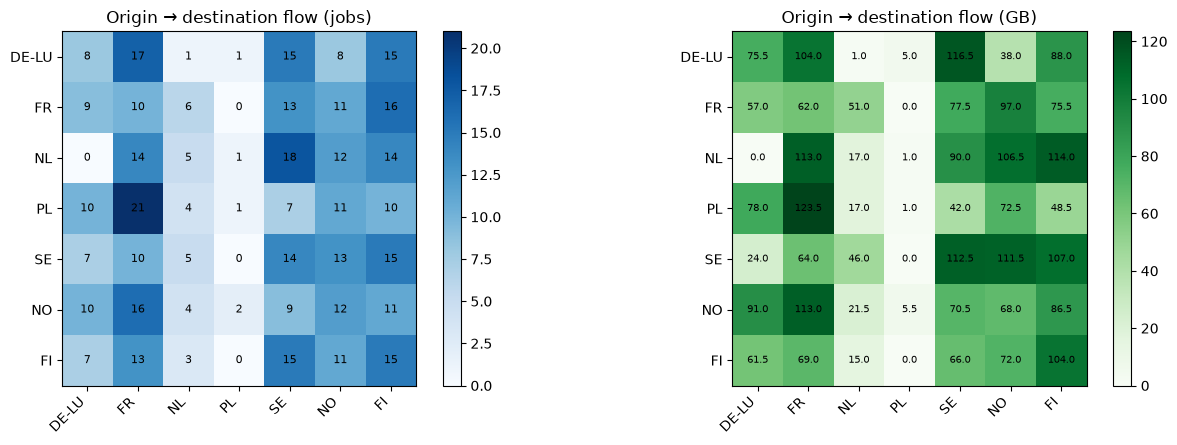

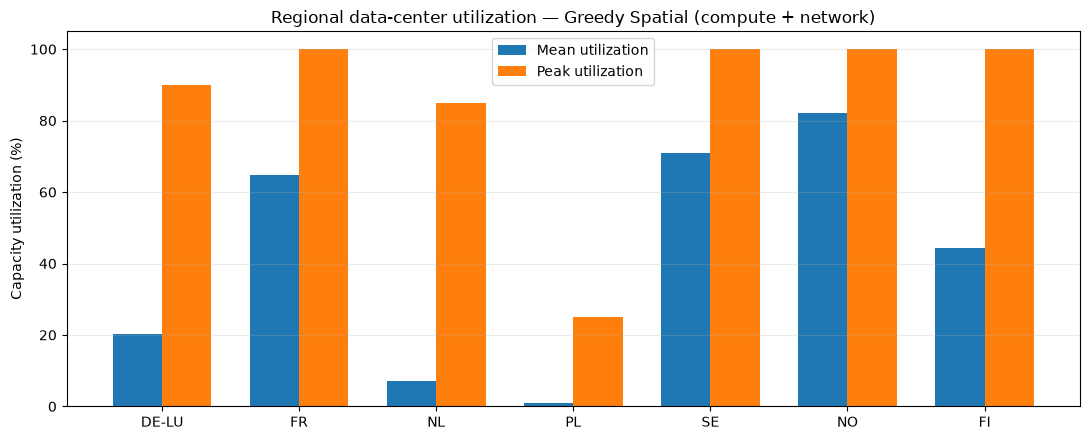

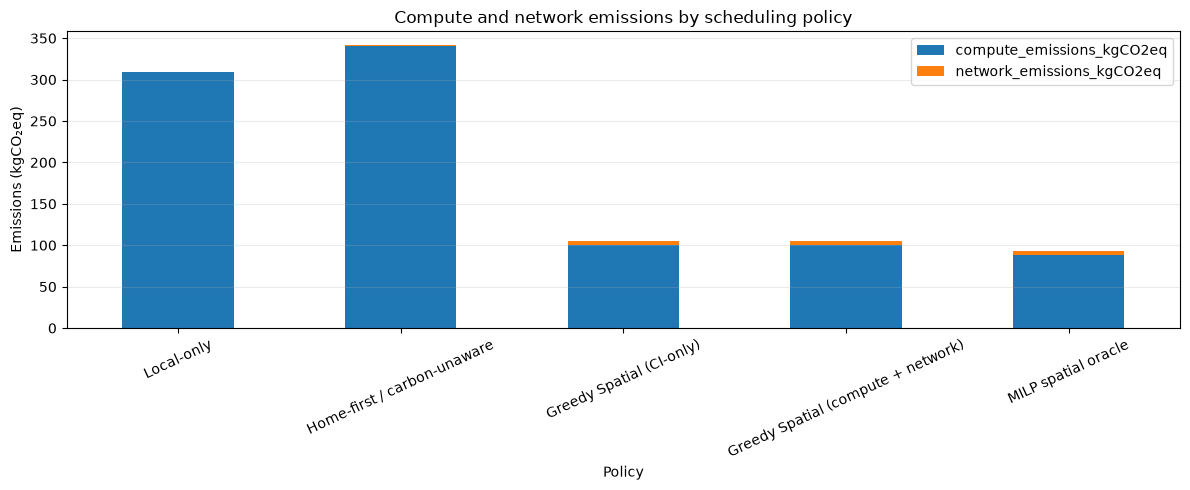

,Compute emissions (%),Network emissions (%),Total carbon reduction vs Local-only (%)
Local-only,100.0000,0.0000,0.0000
Home-first / carbon-unaware,99.6700,0.3300,-10.5500
Greedy Spatial (CI-only),95.8000,4.2000,66.0500
Greedy Spatial (compute + network),95.9200,4.0800,66.0800
MILP spatial oracle,95.8100,4.1900,69.9900


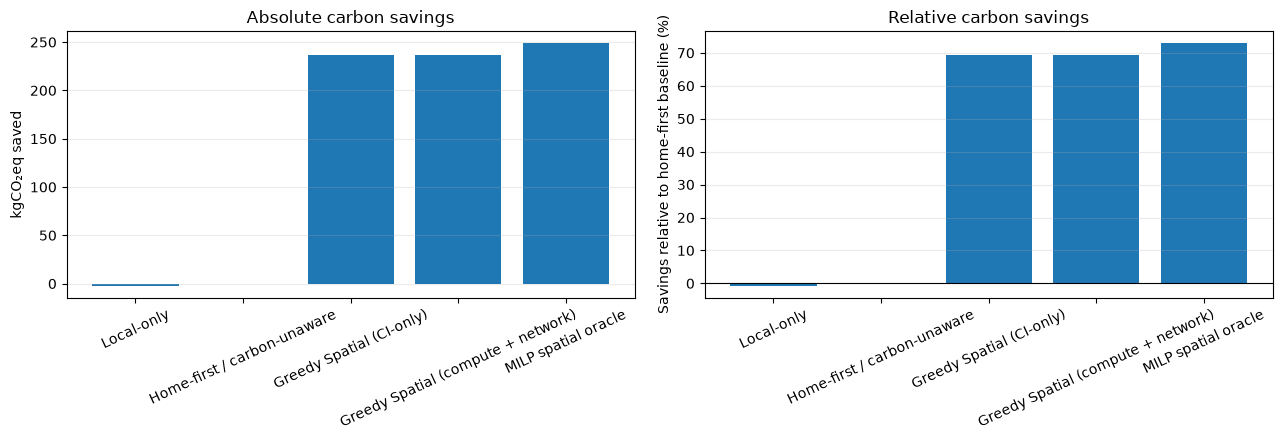

In [54]:
# 13.1 Carbon intensity and assigned regional power for the principal online policy.
main_policy = "Greedy Spatial (compute + network)"
main_schedule = policy_schedules[main_policy]

fig, (ax_ci, ax_power) = plt.subplots(
    2, 1, figsize=(15, 9), sharex=True,
    gridspec_kw={"height_ratios": [1.0, 1.2]},
)

for region in regions:
    ax_ci.plot(slot_hours, ci_day[region], linewidth=1.2, label=region)
ax_ci.set_ylabel("gCO₂eq/kWh")
ax_ci.set_title(f"Regional carbon intensity and spatial workload allocation — {DEMO_DATE}")
ax_ci.legend(ncol=min(4, len(regions)))
ax_ci.grid(True, alpha=0.25)

for region in regions:
    ax_power.step(
        np.arange(HORIZON_SLOTS) * SLOT_HOURS,
        policy_power_loads[main_policy][region],
        where="post",
        linewidth=1.2,
        label=f"{region} load",
    )
    ax_power.axhline(
        float(dc_config.loc[region, "power_capacity_kw"]),
        linestyle=":",
        linewidth=0.8,
        alpha=0.6,
    )
ax_power.set_ylabel("Allocated compute power (kW)")
ax_power.set_xlabel("Elapsed time from start of target day (hours)")
ax_power.set_xlim(0, HORIZON_SLOTS * SLOT_HOURS)
ax_power.set_xticks(np.arange(0, HORIZON_SLOTS * SLOT_HOURS + 0.01, 2))
ax_power.grid(True, alpha=0.25)
ax_power.legend(ncol=min(4, len(regions)))
plt.tight_layout()
plt.show()

# 13.2 Gantt chart: one bar per accepted task, coloured by destination region.
if not main_schedule.empty:
    gantt = main_schedule.sort_values(["release_slot", "task_id"]).reset_index(drop=True)
    region_to_color = {r: plt.get_cmap("tab10")(i % 10) for i, r in enumerate(regions)}

    fig, ax = plt.subplots(figsize=(15, max(5, 0.22 * len(gantt))))
    for row_index, row in gantt.iterrows():
        start_h = int(row["release_slot"]) * SLOT_HOURS
        width_h = float(row["duration_hours"])
        y = row_index
        ax.barh(
            y, width_h, left=start_h, height=0.72,
            color=region_to_color[row["assigned_region"]],
            edgecolor="black", linewidth=0.25,
        )
    ax.set_yticks(np.arange(len(gantt)))
    ax.set_yticklabels(gantt["task_id"], fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(0, HORIZON_SLOTS * SLOT_HOURS)
    ax.set_xticks(np.arange(0, HORIZON_SLOTS * SLOT_HOURS + 0.01, 2))
    ax.set_xlabel("Elapsed time from target-day start (hours)")
    ax.set_ylabel("Task")
    ax.set_title(f"Spatial placement Gantt chart — {main_policy}")
    handles = [
        plt.Line2D([0], [0], color=region_to_color[r], lw=7, label=r)
        for r in regions
    ]
    ax.legend(handles=handles, title="Assigned data center", ncol=min(4, len(regions)))
    ax.grid(True, axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()

# 13.3 Origin-destination migration matrix (job count and transferred volume).
flow_counts = pd.DataFrame(0, index=regions, columns=regions, dtype=int)
flow_data_gb = pd.DataFrame(0.0, index=regions, columns=regions, dtype=float)

for row in main_schedule.itertuples(index=False):
    flow_counts.loc[row.home_region, row.assigned_region] += 1
    flow_data_gb.loc[row.home_region, row.assigned_region] += float(row.transfer_gb)

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.65 * len(regions))))
im0 = axes[0].imshow(flow_counts.to_numpy(), cmap="Blues")
axes[0].set_title("Origin → destination flow (jobs)")
axes[0].set_xticks(np.arange(len(regions)))
axes[0].set_yticks(np.arange(len(regions)))
axes[0].set_xticklabels(regions, rotation=45, ha="right")
axes[0].set_yticklabels(regions)
for i in range(len(regions)):
    for j in range(len(regions)):
        axes[0].text(j, i, str(flow_counts.iloc[i, j]), ha="center", va="center", fontsize=8)
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(flow_data_gb.to_numpy(), cmap="Greens")
axes[1].set_title("Origin → destination flow (GB)")
axes[1].set_xticks(np.arange(len(regions)))
axes[1].set_yticks(np.arange(len(regions)))
axes[1].set_xticklabels(regions, rotation=45, ha="right")
axes[1].set_yticklabels(regions)
for i in range(len(regions)):
    for j in range(len(regions)):
        axes[1].text(j, i, f"{flow_data_gb.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# 13.4 Regional average and peak capacity utilization.
main_util = regional_utilization_by_policy[main_policy]
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(regions))
width = 0.36
ax.bar(
    x - width / 2,
    main_util["mean_capacity_utilization_pct"],
    width,
    label="Mean utilization",
)
ax.bar(
    x + width / 2,
    main_util["peak_capacity_utilization_pct"],
    width,
    label="Peak utilization",
)
ax.set_xticks(x)
ax.set_xticklabels(regions)
ax.set_ylabel("Capacity utilization (%)")
ax.set_title(f"Regional data-center utilization — {main_policy}")
ax.legend()
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 13.5 Total, compute, and network emissions by policy.
emission_columns = [
    "compute_emissions_kgCO2eq",
    "network_emissions_kgCO2eq",
]
emission_plot = metrics_table[emission_columns].copy()
ax = emission_plot.plot(kind="bar", stacked=True, figsize=(12, 5))
ax.set_title("Compute and network emissions by scheduling policy")
ax.set_xlabel("Policy")
ax.set_ylabel("Emissions (kgCO₂eq)")
ax.tick_params(axis="x", rotation=25)
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

local_only_total = metrics_table.loc["Local-only", "total_emissions_kgCO2eq"]

emission_percentages = (
    emission_plot.div(emission_plot.sum(axis=1).replace(0, np.nan), axis=0)
    .mul(100)
    .rename(columns={
        "compute_emissions_kgCO2eq": "Compute emissions (%)",
        "network_emissions_kgCO2eq": "Network emissions (%)",
    })
)
emission_percentages["Total carbon reduction vs Local-only (%)"] = (
    (local_only_total - metrics_table["total_emissions_kgCO2eq"])
    / local_only_total
    * 100
)
display(emission_percentages.round(2))

# 13.6 Carbon savings in kg and percentage relative to the operational baseline.
plot_savings = savings_table.dropna(subset=["carbon_savings_pct"]).copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(plot_savings.index, plot_savings["carbon_savings_kg"])
axes[0].set_title("Absolute carbon savings")
axes[0].set_ylabel("kgCO₂eq saved")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(True, axis="y", alpha=0.25)

axes[1].bar(plot_savings.index, plot_savings["carbon_savings_pct"])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Relative carbon savings")
axes[1].set_ylabel("Savings relative to home-first baseline (%)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 14. Workload-to-region assignment diagnostics

This section compares the job origins with the chosen destinations and checks whether the Greedy Spatial policy actually uses the regional CI differences. A region may receive more work because its carbon signal is cleaner, but its resource ceilings prevent unlimited concentration.

In [48]:
assignment_comparison = pd.DataFrame({
    "Local-only": pd.Series(online_assignment_maps["Local-only"]),
    "Home-first / carbon-unaware": pd.Series(online_assignment_maps["Home-first / carbon-unaware"]),
    "Greedy Spatial (CI-only)": pd.Series(online_assignment_maps["Greedy Spatial (CI-only)"]),
    "Greedy Spatial (compute + network)": pd.Series(online_assignment_maps["Greedy Spatial (compute + network)"]),
})
if "MILP spatial oracle" in online_assignment_maps:
    assignment_comparison["MILP spatial oracle"] = pd.Series(
        online_assignment_maps["MILP spatial oracle"]
    )

destination_counts = pd.DataFrame({
    name: pd.Series(mapping).value_counts().reindex(regions, fill_value=0)
    for name, mapping in online_assignment_maps.items()
}).T
print("Jobs assigned to each data center:")
display(destination_counts)

print("Per-policy assignment map (first 20 jobs):")
display(assignment_comparison.head(20))

# Carbon intensity at arrival, grouped by the region where jobs actually execute.
arrival_ci_rows = []
for policy_name, schedule in policy_schedules.items():
    for row in schedule.itertuples(index=False):
        arrival_ci_rows.append({
            "policy": policy_name,
            "task_id": row.task_id,
            "assigned_region": row.assigned_region,
            "arrival_CI_gCO2eq_kWh": float(
                ci_execution[row.assigned_region][int(row.release_slot)]
            ),
        })
arrival_ci_by_policy = pd.DataFrame(arrival_ci_rows)
if not arrival_ci_by_policy.empty:
    arrival_ci_summary = arrival_ci_by_policy.groupby("policy")[
        "arrival_CI_gCO2eq_kWh"
    ].mean().sort_values()
    display(arrival_ci_summary.to_frame("mean_destination_CI_at_arrival"))

Jobs assigned to each data center:


,DE-LU,FR,NL,PL,SE,NO,FI
Local-only,56,58,58,58,58,55,61
Home-first / carbon-unaware,81,66,67,62,58,55,61
Greedy Spatial (CI-only),50,101,29,5,91,78,96
Greedy Spatial (compute + network),51,101,28,5,91,78,96
MILP spatial oracle,46,91,21,4,106,107,75


Per-policy assignment map (first 20 jobs):


,Local-only,Home-first / carbon-unaware,Greedy Spatial (CI-only),Greedy Spatial (compute + network),MILP spatial oracle
J0001,FR,FR,DE-LU,DE-LU,FR
J0002,FR,FR,NL,NL,NL
J0003,NaN,DE-LU,FI,FI,FI
J0004,FR,FR,NO,NO,FR
J0005,DE-LU,FR,FI,FI,FI
J0006,NO,NO,PL,PL,FI
J0007,FI,FI,FR,FR,NO
J0008,NaN,NL,FR,FR,SE
J0009,NL,NL,FI,FI,NO
J0010,NO,NO,FR,FR,FR


,mean_destination_CI_at_arrival
policy,
MILP spatial oracle,90.0760
Greedy Spatial (CI-only),101.0102
Greedy Spatial (compute + network),101.0388
Local-only,225.7220
Home-first / carbon-unaware,238.3465


## 15. Sensitivity analysis

Two parameters strongly influence spatial-shifting effectiveness:

1. **Network transfer energy (`kWh/GB`):** higher migration overhead reduces the benefit of moving a task to a cleaner region.
2. **Regional capacity:** tighter data-center power and concurrency limits reduce the feasible destination set and may increase immediate-dispatch SLA failures.

The network-energy experiment reruns the online Greedy Spatial policy for each transfer coefficient. The capacity experiment scales all data-center power limits and concurrent-job limits while keeping the workload and carbon-intensity profiles fixed.

,network_kwh_per_gb,baseline_scheduled_jobs,greedy_scheduled_jobs,common_jobs,greedy_migrated_jobs,greedy_savings_kg,greedy_savings_pct
0,0.0000,450,450,450,387,239.7086,70.4808
1,0.0025,450,450,450,386,238.9013,70.1860
2,0.0050,450,450,450,385,238.1169,69.8984
3,0.0100,450,450,450,385,236.5357,69.3210
4,0.0200,450,450,450,385,232.5916,67.9433
5,0.0500,450,450,450,376,223.4972,64.6557


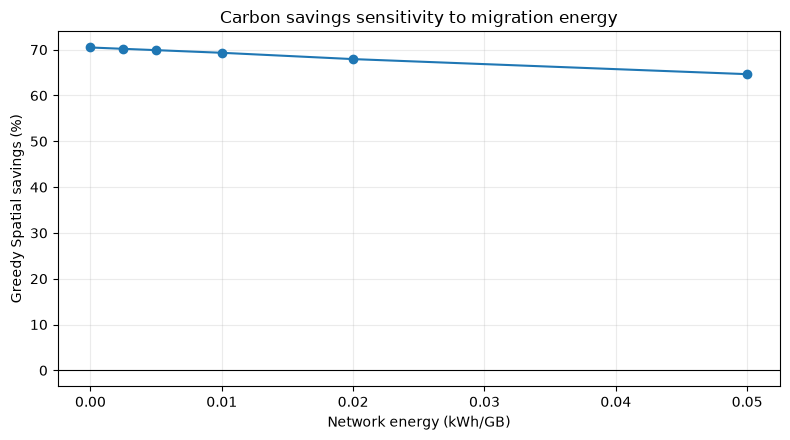

,capacity_scale,baseline_admission_pct,greedy_admission_pct,baseline_SLA_violation_pct,greedy_SLA_violation_pct,common_jobs,greedy_savings_pct_common_jobs
0,0.6000,71.7778,72.0000,28.2222,28.0000,318,21.1100
1,0.8000,98.0000,97.7778,2.0000,2.2222,439,43.9503
2,1.0000,100.0000,100.0000,0.0000,0.0000,450,69.3210
3,1.2000,100.0000,100.0000,0.0000,0.0000,450,69.3178
4,1.4000,100.0000,100.0000,0.0000,0.0000,450,80.1127


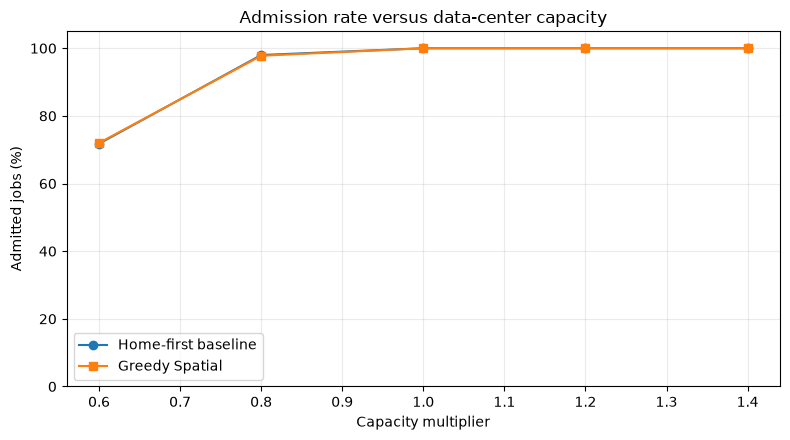

In [49]:
# 15.1 Sensitivity to the transfer-energy coefficient.
network_factors = [0.0, 0.0025, 0.005, 0.01, 0.02, 0.05]
network_sensitivity_rows = []

for factor in network_factors:
    base_map, _, _ = run_online_dispatch(
        tasks, ci_execution, dc_config, "home_first",
        network_kwh_per_gb=factor,
    )
    greedy_map, _, _ = run_online_dispatch(
        tasks, ci_execution, dc_config, "greedy_total",
        network_kwh_per_gb=factor,
    )

    common = sorted(set(base_map) & set(greedy_map))
    base_em = emissions_for_job_subset(
        tasks, base_map, common, ci_execution, factor
    )["total_emissions_kgCO2eq"]
    greedy_em = emissions_for_job_subset(
        tasks, greedy_map, common, ci_execution, factor
    )["total_emissions_kgCO2eq"]

    network_sensitivity_rows.append({
        "network_kwh_per_gb": factor,
        "baseline_scheduled_jobs": len(base_map),
        "greedy_scheduled_jobs": len(greedy_map),
        "common_jobs": len(common),
        "greedy_migrated_jobs": sum(
            greedy_map[j] != str(tasks.set_index("task_id").loc[j, "home_region"])
            for j in greedy_map
        ),
        "greedy_savings_kg": base_em - greedy_em,
        "greedy_savings_pct": (
            100.0 * (base_em - greedy_em) / base_em if base_em > 0 else np.nan
        ),
    })

network_sensitivity = pd.DataFrame(network_sensitivity_rows)
display(network_sensitivity)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    network_sensitivity["network_kwh_per_gb"],
    network_sensitivity["greedy_savings_pct"],
    marker="o",
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Carbon savings sensitivity to migration energy")
ax.set_xlabel("Network energy (kWh/GB)")
ax.set_ylabel("Greedy Spatial savings (%)")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

# 15.2 Sensitivity to regional data-center capacity.
capacity_scales = [0.60, 0.80, 1.00, 1.20, 1.40]
capacity_sensitivity_rows = []

for scale in capacity_scales:
    scaled_config = dc_config.copy()
    scaled_config["power_capacity_kw"] = (
        dc_config["power_capacity_kw"] * scale
    )
    scaled_config["max_concurrent_jobs"] = np.maximum(
        1,
        np.floor(dc_config["max_concurrent_jobs"] * scale).astype(int),
    )

    base_map, _, base_rejected = run_online_dispatch(
        tasks, ci_execution, scaled_config, "home_first"
    )
    greedy_map, _, greedy_rejected = run_online_dispatch(
        tasks, ci_execution, scaled_config, "greedy_total"
    )

    common = sorted(set(base_map) & set(greedy_map))
    base_em = emissions_for_job_subset(
        tasks, base_map, common, ci_execution, NETWORK_KWH_PER_GB
    )["total_emissions_kgCO2eq"]
    greedy_em = emissions_for_job_subset(
        tasks, greedy_map, common, ci_execution, NETWORK_KWH_PER_GB
    )["total_emissions_kgCO2eq"]

    capacity_sensitivity_rows.append({
        "capacity_scale": scale,
        "baseline_admission_pct": 100.0 * len(base_map) / len(tasks),
        "greedy_admission_pct": 100.0 * len(greedy_map) / len(tasks),
        "baseline_SLA_violation_pct": 100.0 * len(base_rejected) / len(tasks),
        "greedy_SLA_violation_pct": 100.0 * len(greedy_rejected) / len(tasks),
        "common_jobs": len(common),
        "greedy_savings_pct_common_jobs": (
            100.0 * (base_em - greedy_em) / base_em if base_em > 0 else np.nan
        ),
    })

capacity_sensitivity = pd.DataFrame(capacity_sensitivity_rows)
display(capacity_sensitivity)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    capacity_sensitivity["capacity_scale"],
    capacity_sensitivity["baseline_admission_pct"],
    marker="o",
    label="Home-first baseline",
)
ax.plot(
    capacity_sensitivity["capacity_scale"],
    capacity_sensitivity["greedy_admission_pct"],
    marker="s",
    label="Greedy Spatial",
)
ax.set_title("Admission rate versus data-center capacity")
ax.set_xlabel("Capacity multiplier")
ax.set_ylabel("Admitted jobs (%)")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## 16. Multi-seed robustness experiment

A single synthetic workload realization can be sensitive to random arrival times and task characteristics. The following experiment repeats the online comparison for multiple workload seeds while keeping the target-day regional carbon signals and infrastructure configuration unchanged.

The MILP oracle is retained for the demonstration workload; the multi-seed experiment focuses on the two online policies to limit repeated solver cost.

In [50]:
robustness_rows = []

for seed in N_WORKLOAD_SEEDS:
    seed_jobs = generate_workload(regions, n_jobs=N_JOBS, seed=int(seed))
    base_map, _, base_reject = run_online_dispatch(
        seed_jobs, ci_execution, dc_config, "home_first"
    )
    greedy_map, _, greedy_reject = run_online_dispatch(
        seed_jobs, ci_execution, dc_config, "greedy_total"
    )

    common = sorted(set(base_map) & set(greedy_map))
    base_em = emissions_for_job_subset(
        seed_jobs, base_map, common, ci_execution, NETWORK_KWH_PER_GB
    )["total_emissions_kgCO2eq"]
    greedy_em = emissions_for_job_subset(
        seed_jobs, greedy_map, common, ci_execution, NETWORK_KWH_PER_GB
    )["total_emissions_kgCO2eq"]

    robustness_rows.append({
        "seed": int(seed),
        "generated_jobs": len(seed_jobs),
        "baseline_scheduled_jobs": len(base_map),
        "greedy_scheduled_jobs": len(greedy_map),
        "baseline_SLA_violation_pct": 100.0 * len(base_reject) / len(seed_jobs),
        "greedy_SLA_violation_pct": 100.0 * len(greedy_reject) / len(seed_jobs),
        "common_jobs": len(common),
        "greedy_savings_kg": base_em - greedy_em,
        "greedy_savings_pct": (
            100.0 * (base_em - greedy_em) / base_em if base_em > 0 else np.nan
        ),
    })

robustness_results = pd.DataFrame(robustness_rows)
display(robustness_results)

print("Multi-seed summary:")
display(robustness_results[[
    "baseline_SLA_violation_pct",
    "greedy_SLA_violation_pct",
    "greedy_savings_pct",
]].agg(["mean", "median", "std", "min", "max"]))

,seed,generated_jobs,baseline_scheduled_jobs,greedy_scheduled_jobs,baseline_SLA_violation_pct,greedy_SLA_violation_pct,common_jobs,greedy_savings_kg,greedy_savings_pct
0,41,450,450,450,0.0000,0.0000,450,240.3431,67.0142
1,42,450,450,450,0.0000,0.0000,450,236.5357,69.3210
2,43,450,450,450,0.0000,0.0000,450,235.5914,70.0792


Multi-seed summary:


,baseline_SLA_violation_pct,greedy_SLA_violation_pct,greedy_savings_pct
mean,0.0000,0.0000,68.8048
median,0.0000,0.0000,69.3210
std,0.0000,0.0000,1.5963
min,0.0000,0.0000,67.0142
max,0.0000,0.0000,70.0792


## 17. Export experiment outputs

The export directory contains the workload, policy schedules, aggregate KPI table, regional utilization, carbon-intensity EDA, migration flows, and sensitivity results. These files can be used to create tables and figures for Section 5.2 of the research report.

In [51]:
# OUTPUT_DIR = Path("spatial_shifting_outputs")
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
#
# tasks.to_csv(OUTPUT_DIR / "synthetic_workload_24h.csv", index=False)
# ci_day.to_csv(OUTPUT_DIR / "regional_carbon_intensity_24h.csv", index=False)
# regional_stats.to_csv(OUTPUT_DIR / "regional_carbon_intensity_statistics.csv")
# pearson_corr.to_csv(OUTPUT_DIR / "regional_ci_pearson_correlation.csv")
# spearman_corr.to_csv(OUTPUT_DIR / "regional_ci_spearman_correlation.csv")
# dc_config.to_csv(OUTPUT_DIR / "datacenter_configuration.csv")
# metrics_table.to_csv(OUTPUT_DIR / "policy_metrics.csv")
# savings_table.to_csv(OUTPUT_DIR / "carbon_savings_vs_home_first.csv")
# destination_counts.to_csv(OUTPUT_DIR / "destination_region_job_counts.csv")
# flow_counts.to_csv(OUTPUT_DIR / "migration_flow_job_counts.csv")
# flow_data_gb.to_csv(OUTPUT_DIR / "migration_flow_data_gb.csv")
# network_sensitivity.to_csv(OUTPUT_DIR / "network_energy_sensitivity.csv", index=False)
# capacity_sensitivity.to_csv(OUTPUT_DIR / "capacity_sensitivity.csv", index=False)
# robustness_results.to_csv(OUTPUT_DIR / "multi_seed_robustness.csv", index=False)
#
# for policy_name, schedule in policy_schedules.items():
#     safe_name = re.sub(r"[^A-Za-z0-9]+", "_", policy_name).strip("_").lower()
#     schedule.to_csv(OUTPUT_DIR / f"schedule_{safe_name}.csv", index=False)
#
# for policy_name, rejected in online_rejections.items():
#     if not rejected.empty:
#         safe_name = re.sub(r"[^A-Za-z0-9]+", "_", policy_name).strip("_").lower()
#         rejected.to_csv(OUTPUT_DIR / f"rejections_{safe_name}.csv", index=False)
#
# pd.Series(milp_solver_info).to_csv(OUTPUT_DIR / "milp_solver_info.csv", header=["value"])
#
# print(f"Outputs saved to: {OUTPUT_DIR.resolve()}")

## 18. Interpretation and limitations

Use the outputs to address the spatial-shifting part of the research:

1. **Regional opportunity:** do the regions exhibit materially different CI levels during the same 24-hour period?
2. **Online routing:** does Greedy Spatial (compute + network) reduce emissions relative to the capacity-aware carbon-unaware baseline?
3. **Migration overhead:** how much of the compute-emission reduction is offset by network emissions?
4. **Capacity constraints:** do regional power or concurrency ceilings prevent concentration in the cleanest region?
5. **SLA impact:** what percentage of arrivals cannot be placed immediately under each policy?
6. **Global optimality gap:** how far is the online heuristic from the retrospective MILP benchmark?
7. **Sensitivity:** how do network energy and data-center capacity change carbon savings and admission performance?

### Important limitations for the thesis

- The carbon signal is the generation-weighted lifecycle estimate developed in Chapter 4. It is an average generation-based signal, not a marginal emissions signal or necessarily a consumption-based regional intensity.
- The ENTSO-E data describe the electricity system; they do not provide cloud-job arrivals, power demand, transfer size, data-center capacity, or network energy. Those workload and infrastructure parameters are synthetic placeholders until calibrated using operational telemetry or literature-supported assumptions.
- All jobs are assumed spatially migratable and eligible for every region. Data-residency, application affinity, user latency, and region-specific eligibility can be added as explicit job constraints.
- Each job is dispatched in its arrival slot and remains in its selected region. The model does not defer work, preempt jobs, or repeatedly migrate running jobs.
- Transfer energy is approximated by `transfer_gb × NETWORK_KWH_PER_GB`. Transfer emissions use the mean CI of the origin and destination at arrival. A route-level network model would be preferable when topology and network telemetry are available.
- Transfer time is not modeled as a delay to execution. The task begins at arrival in the selected region; migration energy is treated as an overhead incurred at dispatch. This assumption should be stated explicitly.
- The MILP uses complete knowledge of the day's arrivals and actual regional carbon-intensity trace. It is an offline benchmark, not a real-time controller.
- If the unshifted local-only policy cannot fit every job, its SLA/admission failures must be reported. Carbon savings against the operational baseline are calculated on the common accepted job set to avoid comparing different amounts of completed work.
- A one-region run is a data-pipeline check only. At least two aligned regional datasets are required to evaluate spatial shifting.

### Recommended reporting practice

Report the selected date, region set, CI data coverage, 15-minute resolution, job count and seed, task duration/power/transfer distributions, per-region capacity and concurrency limits, network-energy coefficient, link bandwidth, solver status/gap, admission rate, compute and network emissions, absolute and percentage carbon savings, and the common-job count used for comparisons.